<a href="https://colab.research.google.com/github/davidlealo/sic_ia_2026/blob/main/ejercicios_profesor/sic2026_ia_clase02_numpy_pandas_ml_profe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIC 2026 · Inteligencia Artificial
## Clase 2: NumPy, pandas y primer modelo de machine learning

**Samsung Innovation Campus Chile 2026 · ONG Innovacien**

En esta clase vamos a repasar las dos librerías que usaremos en todo el curso, NumPy y pandas, y vamos a entrenar nuestro primer modelo de machine learning con datos reales.

| Parte | Tema | Tiempo aproximado |
|---|---|---|
| 0 | Cómo usar este notebook | 10 min |
| 1 | NumPy: cálculo con arreglos | 50 min |
| 2 | pandas: trabajar con tablas de datos | 80 min |
| 3 | Introducción a machine learning | 80 min |
| 4 | Desafío final y guardar en GitHub | 20 min |

**Cómo trabajar:** lee cada explicación, ejecuta las celdas de ejemplo y resuelve los ejercicios marcados con `# TU CÓDIGO AQUÍ`. Después de cada ejercicio hay una celda de verificación que te dice si tu respuesta es correcta. Las soluciones están al final del notebook; intenta resolver cada ejercicio antes de mirarlas.

---
# Parte 0. Cómo usar este notebook

Un notebook de Colab está hecho de **celdas**. Hay dos tipos:

- **Celdas de texto** como esta, con explicaciones.
- **Celdas de código**, que se ejecutan con `Shift + Enter` o con el botón de reproducir a la izquierda.

Las celdas comparten memoria: una variable creada en una celda se puede usar en las siguientes. Por eso es importante ejecutarlas **en orden**. Si algo falla de forma extraña, usa *Entorno de ejecución > Reiniciar y ejecutar todo*.

**Antes de empezar**, guarda tu propia copia: *Archivo > Guardar una copia en Drive*. Así tus cambios no se pierden.

Ejecuta la siguiente celda. Importa las librerías y define una función `revisar` que usaremos para verificar los ejercicios.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def revisar(condicion, mensaje_ok="Correcto.", mensaje_error="Todavía no. Revisa tu respuesta."):
    """Imprime si un ejercicio está bien resuelto."""
    try:
        print(mensaje_ok if condicion() else mensaje_error)
    except Exception:
        print(mensaje_error)

print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.1.3 | pandas 2.2.3


Esta es una celda de texto

# Este es un título

## Título más chico

### Título incluso más chico

*Sección* **nueva**

Ecuación en línea: $E = mc^2$

Ecuación centrada:
$$\hat{y} = \sigma\left(\sum_{i=1}^{n} w_i x_i + b\right)$$

Varias líneas alineadas:
$$
\begin{aligned}
\mathcal{L}(\theta) &= -\frac{1}{N}\sum_{i=1}^{N} y_i \log \hat{y}_i \\
\nabla_\theta \mathcal{L} &= \frac{1}{N}\sum_{i=1}^{N} (\hat{y}_i - y_i)\, x_i
\end{aligned}
$$

In [ ]:
from IPython.display import display, Math, Latex

display(Math(r'\int_0^\infty e^{-x^2}\,dx = \frac{\sqrt{\pi}}{2}'))

# Generar ecuaciones dinámicas con valores calculados
w, b = 0.73, -1.2
display(Math(rf'\hat{{y}} = {w}\,x {b:+}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
%%latex

\begin{equation}
P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)}
\end{equation}

<IPython.core.display.Latex object>

In [ ]:
import sympy as sp
sp.init_printing()

x = sp.symbols('x')
expr = sp.integrate(sp.sin(x)**2, x)
display(expr)          # se ve renderizado
print(sp.latex(expr))  # \frac{x}{2} - \frac{\sin{\left(x \right)} \cos{\left(x \right)}}{2}

x   sin(x)⋅cos(x)
─ - ─────────────
2         2      

\frac{x}{2} - \frac{\sin{\left(x \right)} \cos{\left(x \right)}}{2}


In [ ]:
1 +1

2

In [ ]:
nombre = "David"

In [ ]:
print("Hola", nombre)

NameError: name 'nombre' is not defined

In [ ]:
print("Hola", nombre)

Hola David


In [ ]:
nombre = "David"

---
# Librerías vs. Frameworks

Ambos son código escrito por otras personas que reutilizamos para no partir desde cero. La diferencia está en **quién tiene el control** del flujo del programa.

## Librería

Una **librería** es un conjunto de funciones y clases que **tú llamas** cuando las necesitas. Tu programa decide qué hacer y en qué orden; la librería solo resuelve tareas puntuales.

> Analogía: una caja de herramientas. Tú decides cuándo usar el martillo y cuándo el destornillador.

```python
import math
import random

numero = random.randint(1, 100)   # tú llamas a random
raiz = math.sqrt(numero)          # tú llamas a math
print(f"La raíz de {numero} es {raiz:.2f}")
```

**Ejemplos en Python:** `math`, `random`, `numpy`, `pandas`, `matplotlib`, `requests`.

## Framework

Un **framework** es una estructura que define cómo debe organizarse tu programa. **El framework llama a tu código** en los momentos que él determina. Tú completas las piezas que faltan.

> Analogía: una casa prefabricada. La estructura ya está; tú eliges los muebles y la pintura, pero no puedes mover las paredes maestras.

```python
from flask import Flask

app = Flask(__name__)

@app.route("/")
def inicio():               # tú escribes la función...
    return "¡Hola mundo!"

app.run()                   # ...pero Flask decide cuándo llamarla
```

Aquí nunca llamamos a `inicio()` directamente: Flask la ejecuta cuando alguien visita la página.

**Ejemplos en Python:** `Django`, `Flask`, `FastAPI`, `pytest`, `PyTorch Lightning`.

## Inversión de control

La idea clave que los distingue se llama **inversión de control**:

- Con una **librería**, tu código llama a la librería.
- Con un **framework**, el framework llama a tu código.

## Comparación

| Aspecto | Librería | Framework |
|---|---|---|
| ¿Quién controla el flujo? | Tu programa | El framework |
| Flexibilidad | Alta: la usas como quieras | Menor: sigues sus reglas |
| Estructura del proyecto | La defines tú | Viene predefinida |
| Curva de aprendizaje | Generalmente baja | Generalmente mayor |
| Ejemplo | `pandas` | `Django` |

## ¿Cuál usar?

- Usa **librerías** cuando necesitas resolver tareas específicas (cálculos, gráficos, leer archivos).
- Usa un **framework** cuando construyes algo grande con una estructura conocida (una aplicación web, una API, una batería de tests), y quieres aprovechar decisiones ya tomadas por otros.

En la práctica, los proyectos combinan ambos: por ejemplo, una aplicación en `Django` (framework) que usa `pandas` y `matplotlib` (librerías) para generar reportes.

## Para pensar

1. ¿`numpy` es una librería o un framework? ¿Por qué?
2. En el ejemplo de Flask, ¿qué pasaría si eliminamos la línea `app.run()`?
3. Nombra una situación en la que preferirías no usar un framework.

In [ ]:
# Cómo saco la raíz de cuadrada de un número sin librerias?

def raiz(numero):
    return numero ** 0.5

raiz(16)

4.0

In [ ]:
raiz(25)

5.0

In [ ]:
import math

math.sqrt(25)

5.0

# El módulo `math` de Python: casos de uso simples y complejos

> Fuente: documentación oficial de Python, [`math` — Mathematical functions](https://docs.python.org/3/library/math.html)

El módulo `math` ofrece funciones y constantes matemáticas de uso común, muchas de ellas basadas en las definidas por el estándar de C. Según la documentación, salvo que se indique lo contrario, **todas sus funciones devuelven valores `float`**. Además, **no trabaja con números complejos**: para eso existe el módulo [`cmath`](https://docs.python.org/3/library/cmath.html).

```python
import math
```

---

## Parte 1: Casos de uso simples

### 1.1 Redondear hacia arriba o hacia abajo

**Problema:** un curso tiene 47 estudiantes y cada sala admite 20. ¿Cuántas salas se necesitan?

```python
estudiantes = 47
capacidad = 20

salas = math.ceil(estudiantes / capacidad)
print(salas)  # 3
```

- `ceil(x)` devuelve el menor entero mayor o igual a `x`.
- `floor(x)` devuelve el mayor entero menor o igual a `x`.
- `trunc(x)` elimina la parte decimal, redondeando siempre hacia 0.

```python
print(math.floor(-2.7))  # -3
print(math.trunc(-2.7))  # -2  (hacia el cero)
```

📖 Referencias: [`ceil`](https://docs.python.org/3/library/math.html#math.ceil) · [`floor`](https://docs.python.org/3/library/math.html#math.floor) · [`trunc`](https://docs.python.org/3/library/math.html#math.trunc)

### 1.2 Raíces y el teorema de Pitágoras

```python
print(math.sqrt(16))      # 4.0
print(math.hypot(3, 4))   # 5.0  -> hipotenusa de un triángulo de catetos 3 y 4
```

`hypot` calcula la longitud de un vector desde el origen; en dos dimensiones equivale a aplicar Pitágoras.

📖 Referencias: [`sqrt`](https://docs.python.org/3/library/math.html#math.sqrt) · [`hypot`](https://docs.python.org/3/library/math.html#math.hypot)

### 1.3 Geometría con constantes

```python
radio = 5
area = math.pi * radio ** 2
perimetro = math.tau * radio   # tau = 2π

print(f"Área: {area:.2f}, Perímetro: {perimetro:.2f}")
```

📖 Referencias: [`pi`](https://docs.python.org/3/library/math.html#math.pi) · [`tau`](https://docs.python.org/3/library/math.html#math.tau)

### 1.4 Trigonometría: grados vs. radianes

Las funciones trigonométricas reciben el ángulo **en radianes**. Un error típico es pasarles grados.

```python
print(math.sin(90))                  # 0.8939...  ❌ (90 radianes)
print(math.sin(math.radians(90)))    # 1.0        ✅
print(math.degrees(math.pi))         # 180.0
```

📖 Referencias: [`sin`](https://docs.python.org/3/library/math.html#math.sin) · [`radians`](https://docs.python.org/3/library/math.html#math.radians) · [`degrees`](https://docs.python.org/3/library/math.html#math.degrees)

### 1.5 Logaritmos: ¿cuántos pasos necesita una búsqueda binaria?

```python
n = 1_000_000
pasos = math.ceil(math.log2(n))
print(pasos)  # 20
```

La documentación indica que `log2(x)` suele ser más preciso que `log(x, 2)`, y lo mismo ocurre con `log10`.

📖 Referencias: [`log`](https://docs.python.org/3/library/math.html#math.log) · [`log2`](https://docs.python.org/3/library/math.html#math.log2) · [`log10`](https://docs.python.org/3/library/math.html#math.log10)

### 1.6 Combinatoria: ¿cuántos equipos de 2 se forman con 5 personas?

```python
print(math.comb(5, 2))     # 10  (sin importar el orden)
print(math.perm(5, 2))     # 20  (importa el orden)
print(math.factorial(5))   # 120
```

> ⚠️ Desde Python 3.15 estas funciones se encuentran en el submódulo [`math.integer`](https://docs.python.org/3/library/math.integer.html); en `math` se mantienen como alias por compatibilidad.

📖 Referencia: [Number-theoretic functions](https://docs.python.org/3/library/math.html#number-theoretic-functions)

---

## Parte 2: Casos de uso complejos

### 2.1 Comparar números decimales correctamente

Los `float` tienen errores de representación, por lo que `==` puede fallar:

```python
print(0.1 + 0.2 == 0.3)                # False
print(math.isclose(0.1 + 0.2, 0.3))    # True
```

`isclose` usa una **tolerancia relativa** (`rel_tol`, por defecto `1e-09`, unos 9 dígitos decimales) y una **tolerancia absoluta** (`abs_tol`, por defecto `0.0`).

**Trampa importante:** al comparar con cero, la tolerancia relativa no sirve, así que la documentación recomienda agregar un `abs_tol` positivo:

```python
print(math.isclose(1e-10, 0))                  # False
print(math.isclose(1e-10, 0, abs_tol=1e-9))    # True
```

📖 Referencia: [`isclose`](https://docs.python.org/3/library/math.html#math.isclose) · [PEP 485](https://peps.python.org/pep-0485/)

### 2.2 Sumas sin pérdida de precisión

```python
valores = [0.1] * 10

print(sum(valores))        # 0.9999999999999999
print(math.fsum(valores))  # 1.0
```

`fsum` evita la pérdida de precisión manteniendo varias sumas parciales intermedias. Es útil al acumular muchos valores pequeños, como métricas promediadas en experimentos.

📖 Referencia: [`fsum`](https://docs.python.org/3/library/math.html#math.fsum)

### 2.3 Distancias y similitud entre vectores

**Distancia euclidiana** (base de algoritmos como k-vecinos más cercanos):

```python
p = (1, 2, 3)
q = (4, 6, 3)
print(math.dist(p, q))  # 5.0
```

**Similitud coseno** (muy usada en sistemas de recomendación y embeddings):

```python
def similitud_coseno(a, b):
    return math.sumprod(a, b) / (math.hypot(*a) * math.hypot(*b))

usuario_1 = [5, 3, 0, 1]
usuario_2 = [4, 2, 0, 1]
print(round(similitud_coseno(usuario_1, usuario_2), 4))  # 0.9945
```

`sumprod` calcula el producto punto con precisión extendida en los pasos intermedios y lanza `ValueError` si los vectores tienen distinto largo.

📖 Referencias: [`dist`](https://docs.python.org/3/library/math.html#math.dist) · [`sumprod`](https://docs.python.org/3/library/math.html#math.sumprod) (Python 3.12+) · [`hypot`](https://docs.python.org/3/library/math.html#math.hypot)

### 2.4 Estadística: la distribución normal sin librerías externas

La documentación muestra que la función de error `erf` permite calcular la función de distribución acumulada de la normal estándar:

```python
def phi(x):
    """Probabilidad acumulada de la normal estándar hasta x."""
    return (1.0 + math.erf(x / math.sqrt(2.0))) / 2.0

print(round(phi(1.96), 4))   # 0.975  -> base del intervalo de confianza al 95 %
```

📖 Referencias: [`erf`](https://docs.python.org/3/library/math.html#math.erf) · [`erfc`](https://docs.python.org/3/library/math.html#math.erfc)

### 2.5 Precisión numérica cerca de cero: `expm1` y `log1p`

Restar 1 a `exp(x)` cuando `x` es muy pequeño provoca pérdida de cifras significativas. Estas funciones lo resuelven:

```python
x = 1e-5
print(math.exp(x) - 1)   # 1.0000050000069649e-05  (menos preciso)
print(math.expm1(x))     # 1.0000050000166668e-05  (precisión completa)
```

Aplicación en aprendizaje automático, la función de activación *softplus*:

```python
def softplus(x):
    return math.log1p(math.exp(x))   # log(1 + e^x)

print(softplus(0.0))  # 0.6931... = log(2)
```

📖 Referencias: [`expm1`](https://docs.python.org/3/library/math.html#math.expm1) · [`log1p`](https://docs.python.org/3/library/math.html#math.log1p)

### 2.6 Ángulos en el cuadrante correcto con `atan2`

`atan(y / x)` pierde los signos de `x` e `y`, por lo que no distingue cuadrantes. `atan2(y, x)` sí los conoce:

```python
print(math.degrees(math.atan(-1 / -1)))   # 45.0    ❌ cuadrante equivocado
print(math.degrees(math.atan2(-1, -1)))   # -135.0  ✅
```

Útil en robótica, videojuegos o para calcular la dirección de movimiento de un objeto.

📖 Referencia: [`atan2`](https://docs.python.org/3/library/math.html#math.atan2)

### 2.7 Valores especiales: infinito y NaN

`NaN` ("no es un número") **no es igual a nada, ni siquiera a sí mismo**:

```python
print(math.nan == math.nan)   # False
print(math.isnan(math.nan))   # True
```

Como dice la documentación: *"To check whether a number is a NaN, use the isnan() function"*.

Ejemplo práctico, limpiar mediciones inválidas:

```python
mediciones = [12.5, math.nan, 13.1, math.inf, 11.8]
validas = [m for m in mediciones if math.isfinite(m)]
print(validas)  # [12.5, 13.1, 11.8]
```

📖 Referencias: [`nan`](https://docs.python.org/3/library/math.html#math.nan) · [`isnan`](https://docs.python.org/3/library/math.html#math.isnan) · [`isfinite`](https://docs.python.org/3/library/math.html#math.isfinite) · [`inf`](https://docs.python.org/3/library/math.html#math.inf)

### 2.8 Manejo de errores

En CPython, las operaciones inválidas lanzan `ValueError` y los resultados demasiado grandes lanzan `OverflowError`:

```python
for funcion, valor in [(math.sqrt, -1), (math.log, 0), (math.exp, 1000)]:
    try:
        print(funcion(valor))
    except ValueError:
        print(f"{funcion.__name__}({valor}): operación inválida")
    except OverflowError:
        print(f"{funcion.__name__}({valor}): resultado demasiado grande")
```

> Para la raíz de un número negativo, usa `cmath.sqrt(-1)`, que devuelve `1j`.

📖 Referencia: [CPython implementation detail](https://docs.python.org/3/library/math.html#constants)

---

## Resumen

| Necesidad | Función |
|---|---|
| Redondear | `ceil`, `floor`, `trunc` |
| Raíces y distancias | `sqrt`, `hypot`, `dist` |
| Comparar floats | `isclose` |
| Sumar con precisión | `fsum` |
| Producto punto | `sumprod` |
| Estadística normal | `erf` |
| Precisión cerca de cero | `expm1`, `log1p` |
| Ángulos | `radians`, `degrees`, `atan2` |
| Validar datos | `isnan`, `isinf`, `isfinite` |

## Para practicar

1. ¿Por qué `math.isclose(x, 0)` devuelve `False` para cualquier `x` distinto de cero si no se usa `abs_tol`?
2. Escribe una función que calcule la distancia entre dos ciudades dadas sus coordenadas en un plano.
3. Usando `phi`, calcula la probabilidad de que una variable normal estándar esté entre -1 y 1.

In [ ]:
pi = 3.14

In [ ]:
import math

math.pi

3.141592653589793

---

# Versiones de Python: historia y diferencias principales

## ¿Cómo se numeran las versiones?

Python usa el formato **`MAYOR.MENOR.PARCHE`**, por ejemplo `3.12.4`:

| Parte | Ejemplo | Significado |
|---|---|---|
| Mayor | `3` | Cambios profundos e incompatibles con la versión anterior (de 2 a 3) |
| Menor | `12` | Nuevas funcionalidades. Sale **una por año, cada octubre** |
| Parche | `4` | Corrección de errores y de seguridad, sin funciones nuevas |

```python
import sys
print(sys.version)        # versión completa
print(sys.version_info)   # sys.version_info(major=3, minor=12, ...)
```

En Colab o en una terminal también puedes usar:

```
!python --version
```

---

## Python 2 vs. Python 3

Python 3 (2008) rompió la compatibilidad con Python 2 para corregir problemas de diseño. **Python 2 dejó de recibir soporte el 1 de enero de 2020** y hoy no debería usarse en proyectos nuevos.

| Aspecto | Python 2 | Python 3 |
|---|---|---|
| Imprimir | `print "Hola"` | `print("Hola")` |
| División | `5 / 2` → `2` | `5 / 2` → `2.5` (usa `//` para división entera) |
| Texto | ASCII por defecto | Unicode por defecto (tildes y ñ sin problemas) |
| `range` | Crea una lista completa | Genera valores bajo demanda |

---

## Novedades principales de cada versión de Python 3

### Python 3.6 (2016): f-strings

```python
nombre = "Ana"
print(f"Hola, {nombre}")
```

### Python 3.7 (2018): dataclasses y diccionarios ordenados

```python
from dataclasses import dataclass

@dataclass
class Punto:
    x: float
    y: float

print(Punto(1, 2))  # Punto(x=1, y=2)
```

Desde esta versión, el orden de inserción de los diccionarios está garantizado.

### Python 3.8 (2019): operador morsa `:=` y depuración con f-strings

```python
if (n := len([1, 2, 3])) > 2:
    print(f"Lista larga: {n=}")   # Lista larga: n=3
```

### Python 3.9 (2020): unión de diccionarios y tipos simplificados

```python
a = {"x": 1}
b = {"y": 2}
print(a | b)                 # {'x': 1, 'y': 2}

def promedio(notas: list[float]) -> float:   # antes: List[float] de typing
    return sum(notas) / len(notas)

print("archivo.txt".removesuffix(".txt"))    # archivo
```

### Python 3.10 (2021): `match` / `case`

Coincidencia de patrones estructurales, similar a un `switch` pero más potente:

```python
def responder(comando):
    match comando.split():
        case ["salir"]:
            return "Adiós"
        case ["ir", direccion]:
            return f"Yendo hacia {direccion}"
        case _:
            return "Comando desconocido"

print(responder("ir norte"))  # Yendo hacia norte
```

También permite escribir tipos como `int | None` y mejoró mucho los mensajes de error.

### Python 3.11 (2022): mucho más rápido

- Mejora de velocidad promedio cercana al **25 %** respecto de 3.10 (proyecto *Faster CPython*).
- Mensajes de error que señalan la **posición exacta** del problema en la línea.
- `ExceptionGroup` y `except*` para manejar varios errores a la vez.
- Módulo `tomllib` para leer archivos de configuración TOML.

### Python 3.12 (2023): f-strings más flexibles y genéricos simples

```python
usuario = {"nombre": "Ana"}
print(f"Hola, {usuario["nombre"]}")   # ahora se pueden repetir comillas dentro

type Vector = list[float]             # nueva sintaxis para alias de tipos

def primero[T](elementos: list[T]) -> T:   # genéricos sin TypeVar
    return elementos[0]
```

También agregó `itertools.batched` y `math.sumprod`.

### Python 3.13 (2024): nueva consola y experimentos de rendimiento

- Nueva consola interactiva (REPL) con colores y edición de varias líneas.
- Versión **experimental sin GIL** (*free-threaded*), que permite que varios hilos ejecuten código Python en paralelo.
- Compilador **JIT experimental**.
- Se eliminaron módulos antiguos de la biblioteca estándar (como `cgi`).

### Python 3.14 (2025): t-strings y paralelismo real

- **Template strings** (`t"..."`): parecidos a las f-strings, pero permiten procesar el texto antes de unirlo, útil para evitar inyecciones en SQL o HTML.
- La versión sin GIL pasa a tener **soporte oficial** (aunque sigue siendo opcional).
- Evaluación diferida de anotaciones de tipo.
- Soporte de compresión `zstd` en la biblioteca estándar.

### Python 3.15 (octubre 2026): la versión más reciente

- **Importaciones diferidas** con la palabra clave `lazy`, que aceleran el inicio de programas grandes:

```python
  lazy import pandas   # solo se carga cuando se usa por primera vez
```

- Nuevo tipo inmutable **`frozendict`** y nuevo tipo **`sentinel`**.
- **UTF-8 pasa a ser la codificación por defecto** al abrir archivos.
- Nuevo paquete `profiling` con un perfilador estadístico de bajo costo.
- Compilador JIT experimental más rápido y mejores mensajes de error.

---

## Resumen

| Versión | Año | Novedad más recordada |
|---|---|---|
| 3.6 | 2016 | f-strings |
| 3.7 | 2018 | `dataclasses` |
| 3.8 | 2019 | operador `:=` |
| 3.9 | 2020 | `dict1 \| dict2`, `list[int]` |
| 3.10 | 2021 | `match` / `case` |
| 3.11 | 2022 | ~25 % más rápido |
| 3.12 | 2023 | f-strings flexibles, `type` |
| 3.13 | 2024 | nueva consola, sin GIL experimental |
| 3.14 | 2025 | t-strings, sin GIL oficial |
| 3.15 | 2026 | `lazy import`, `frozendict`, UTF-8 por defecto |

---

## Ciclo de vida y soporte

Cada versión menor recibe soporte durante **unos 5 años**:

1. **Bugfix:** se corrigen errores y problemas de seguridad, y se publican instaladores.
2. **Security:** solo se corrigen problemas de seguridad.
3. **End-of-life (fin de vida):** no recibe más cambios. Usarla es un riesgo.

A octubre de 2026, las versiones **3.9 y anteriores ya no tienen soporte**, y la 3.10 llega a su fin de vida este mismo mes. El estado actualizado de cada versión está en la [guía oficial de versiones](https://devguide.python.org/versions/).

---

## ¿Qué versión usar?

- **Proyectos nuevos:** una versión reciente con soporte activo (3.13 o 3.14 son opciones seguras).
- **La última versión (3.15):** ideal para explorar novedades, pero algunas librerías como `numpy`, `pandas` o `torch` pueden tardar unos meses en ser totalmente compatibles.
- **Colab y servicios en la nube:** usan la versión que define el proveedor, que suele ir una o dos versiones atrás. Revísala con `!python --version` antes de usar funciones nuevas.
- **Código heredado:** si un proyecto usa una versión sin soporte, conviene planificar su actualización.

## Para practicar

1. Revisa qué versión de Python tienes en Colab. ¿Puedes usar `match` / `case`? ¿Y `math.sumprod`?
2. Reescribe este código de Python 2 en Python 3: `print "Promedio:", 7 / 2`
3. ¿Por qué crees que Python 3 decidió romper la compatibilidad con Python 2?

## Fuentes

- [Status of Python versions (Python Developer's Guide)](https://devguide.python.org/versions/)
- [What's New in Python](https://docs.python.org/3/whatsnew/index.html)
- [What's New in Python 3.15](https://docs.python.org/3/whatsnew/3.15.html)


In [ ]:
#Imprimir la version de Python

import sys

print(sys.version)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


---
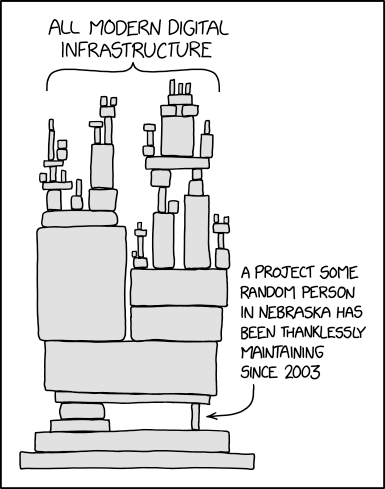

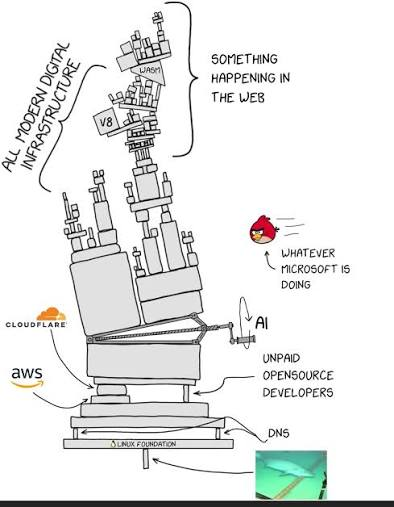

# El array de NumPy (`ndarray`)

## ¿Qué es?

El **array de NumPy** (`numpy.ndarray`) es una estructura de datos que guarda una colección de valores **del mismo tipo** organizados en una o más dimensiones. Es la base de casi todo el ecosistema científico de Python: `pandas`, `matplotlib`, `scikit-learn` y `PyTorch` lo usan o se inspiran en él.

```python
import numpy as np

arr = np.array([1, 2, 3, 4])
print(arr)        # [1 2 3 4]
print(type(arr))  # <class 'numpy.ndarray'>
```

---

## Array vs. lista de Python

A primera vista se parecen, pero se comportan de forma muy distinta:

```python
lista = [1, 2, 3]
arr = np.array([1, 2, 3])

print(lista * 2)   # [1, 2, 3, 1, 2, 3]  -> repite la lista
print(arr * 2)     # [2 4 6]             -> multiplica cada elemento
```

| Característica | Lista de Python | Array de NumPy |
|---|---|---|
| Tipos de datos | Puede mezclar tipos | Un solo tipo para todos los elementos |
| Operaciones matemáticas | Requieren ciclos `for` | Se aplican a todos los elementos a la vez |
| Velocidad | Lenta para cálculos numéricos | Mucho más rápida (implementada en C) |
| Memoria | Mayor consumo | Datos compactos y contiguos |
| Dimensiones | Listas anidadas | Soporte nativo para matrices y tensores |

### ¿Cuánto más rápido?

```python
numeros = list(range(1_000_000))
arr = np.arange(1_000_000)

%timeit [x * 2 for x in numeros]   # ciclo en Python
%timeit arr * 2                    # operación vectorizada
```

La versión con NumPy suele ser decenas de veces más rápida.

---

## Crear arrays

```python
np.array([1, 2, 3])            # desde una lista
np.zeros((2, 3))               # matriz de 2x3 llena de ceros
np.ones(4)                     # [1. 1. 1. 1.]
np.full((2, 2), 7)             # matriz de 2x2 llena de sietes
np.arange(0, 10, 2)            # [0 2 4 6 8]  (como range)
np.linspace(0, 1, 5)           # [0.   0.25 0.5  0.75 1.  ] (5 valores equiespaciados)
np.eye(3)                      # matriz identidad de 3x3
np.random.rand(2, 3)           # matriz de 2x3 con valores aleatorios entre 0 y 1
```

---

## Atributos principales

```python
m = np.array([[1, 2, 3],
              [4, 5, 6]])

print(m.shape)   # (2, 3)  -> 2 filas, 3 columnas
print(m.ndim)    # 2       -> número de dimensiones
print(m.size)    # 6       -> total de elementos
print(m.dtype)   # int64   -> tipo de dato
```

### Dimensiones

| `ndim` | Nombre común | Ejemplo |
|---|---|---|
| 0 | Escalar | `np.array(5)` |
| 1 | Vector | `np.array([1, 2, 3])` |
| 2 | Matriz | `np.array([[1, 2], [3, 4]])` |
| 3 o más | Tensor | Una imagen a color: alto × ancho × 3 canales |

### Tipos de datos (`dtype`)

Como todos los elementos deben tener el mismo tipo, NumPy convierte automáticamente al tipo más general:

```python
print(np.array([1, 2.5]).dtype)    # float64  -> el entero se convierte a decimal
print(np.array([1, "a"]))          # ['1' 'a'] -> todo se convierte a texto
```

---

## Acceder a los elementos

### Índices y slicing

```python
m = np.array([[1, 2, 3],
              [4, 5, 6]])

print(m[0, 1])    # 2         -> fila 0, columna 1
print(m[1])       # [4 5 6]   -> fila completa
print(m[:, 1])    # [2 5]     -> columna completa
print(m[:, 1:])   # [[2 3]
                  #  [5 6]]   -> todas las filas, desde la columna 1
```

### Filtrado con condiciones (indexación booleana)

```python
notas = np.array([5.5, 3.9, 6.8, 4.0, 2.5])

print(notas >= 4.0)          # [ True False  True  True False]
print(notas[notas >= 4.0])   # [5.5 6.8 4. ]  -> solo los aprobados
print((notas >= 4.0).sum())  # 3              -> cuántos aprobaron
```

---

## Operaciones

### Operaciones elemento a elemento

```python
a = np.array([1, 2, 3])
b = np.array([10, 20, 30])

print(a + b)       # [11 22 33]
print(a * b)       # [10 40 90]
print(a ** 2)      # [1 4 9]
print(np.sqrt(a))  # [1.         1.41421356 1.73205081]
```

### Agregaciones y el parámetro `axis`

```python
m = np.array([[1, 2, 3],
              [4, 5, 6]])

print(m.sum())           # 21          -> todos los elementos
print(m.sum(axis=0))     # [5 7 9]     -> suma por columna (recorre las filas)
print(m.sum(axis=1))     # [ 6 15]     -> suma por fila (recorre las columnas)
print(m.mean(), m.max(), m.min(), m.std())
```

> Truco para recordar `axis`: es la dimensión que **desaparece**. Con `axis=0` se colapsan las filas y queda un valor por columna.

### Producto matricial

```python
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print(A * B)   # multiplicación elemento a elemento
print(A @ B)   # producto matricial: [[19 22] [43 50]]
```

---

## Broadcasting

NumPy puede operar con arrays de formas distintas "estirando" el más pequeño cuando las dimensiones son compatibles:

```python
m = np.array([[1, 2, 3],
              [4, 5, 6]])
fila = np.array([10, 20, 30])

print(m + fila)
# [[11 22 33]
#  [14 25 36]]
```

La fila se suma a cada fila de la matriz sin necesidad de un ciclo. Lo mismo ocurre con `m * 2`, donde el escalar se aplica a todos los elementos.

---

## Cambiar la forma

```python
arr = np.arange(6)            # [0 1 2 3 4 5]

print(arr.reshape(2, 3))      # [[0 1 2]
                              #  [3 4 5]]
print(arr.reshape(3, -1))     # -1 calcula la dimensión automáticamente: 3x2
print(arr.reshape(2, 3).T)    # transpuesta: 3x2
print(arr.reshape(2, 3).flatten())   # vuelve a 1 dimensión
```

---

## ⚠️ Cuidado: vistas vs. copias

Un slicing **no crea una copia**, sino una *vista* que comparte memoria con el original:

```python
a = np.array([1, 2, 3, 4])
b = a[:2]
b[0] = 99

print(a)   # [99  2  3  4]  -> ¡el original también cambió!
```

Para trabajar de forma independiente, usa `.copy()`:

```python
c = a[:2].copy()
c[0] = 0
print(a)   # [99  2  3  4]  -> el original no cambia
```

---

## Resumen

| Necesidad | Código |
|---|---|
| Crear desde lista | `np.array([...])` |
| Secuencia de números | `np.arange`, `np.linspace` |
| Ver forma y tipo | `.shape`, `.dtype` |
| Seleccionar columna | `m[:, j]` |
| Filtrar | `arr[arr > valor]` |
| Sumar por fila o columna | `.sum(axis=...)` |
| Producto matricial | `A @ B` |
| Cambiar forma | `.reshape(...)` |
| Copia independiente | `.copy()` |

## Para practicar

1. Crea un array con las notas de 10 estudiantes y calcula el promedio, la nota máxima y cuántos reprobaron.
2. Crea una matriz de 3x4 con `np.arange` y `reshape`, y obtén la suma de cada columna.
3. ¿Qué imprime `np.array([1, 2, 3]) + np.array([[10], [20]])`? Explica el resultado usando broadcasting.
4. Explica por qué este código modifica `a`: `b = a[1:3]; b[:] = 0`.

## Fuentes

- [NumPy: the absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html)
- [The N-dimensional array (`ndarray`)](https://numpy.org/doc/stable/reference/arrays.ndarray.html)
- [Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html)

In [ ]:
# RANGE built in function in Python

for i in range(0,31):
  print(i)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30


In [ ]:
import numpy

for i in numpy.arange(0,31):
  print(i)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30


In [ ]:
import numpy as pepito

for i in pepito.arange(0,31):
  print(i)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30


In [ ]:
import numpy as np

np.ones(5)

array([1., 1., 1., 1., 1.])

In [ ]:
np.zeros(5)

array([0., 0., 0., 0., 0.])

In [ ]:
np.ones((5,), dtype=np.int_)

array([1, 1, 1, 1, 1])

In [ ]:
np.ones((2, 1))

array([[1.],
       [1.]])

In [ ]:
import numpy as np
x = np.arange(6)
x

array([0, 1, 2, 3, 4, 5])

In [ ]:
x = x.reshape((2, 3))
x

array([[0, 1, 2],
       [3, 4, 5]])

In [ ]:
np.ones_like(x)

array([[1, 1, 1],
       [1, 1, 1]])

# Cómo leer la documentación de NumPy

## Caso de estudio: `numpy.ones`

> Página analizada: [numpy.ones — NumPy Manual](https://numpy.org/doc/stable/reference/generated/numpy.ones.html)

Leer documentación es una habilidad tan importante como programar. Nadie memoriza todas las funciones de una librería: los programadores con experiencia saben **dónde buscar** y **cómo interpretar** lo que encuentran. En este tutorial vamos a recorrer una página completa de la documentación de NumPy, sección por sección.

```python
import numpy as np
```

---

## Paso 1: Ubícate en el sitio

### Las grandes secciones

La documentación de NumPy tiene varias partes en el menú superior. Las dos más importantes para empezar son:

| Sección | Para qué sirve | Cuándo usarla |
|---|---|---|
| **User Guide** | Explicaciones y tutoriales por tema | Cuando quieres **aprender un concepto** |
| **API reference** | Ficha técnica de cada función | Cuando quieres saber **cómo usar una función concreta** |

La página de `numpy.ones` pertenece a la **API reference**.

### La ruta de navegación (*breadcrumbs*)

Sobre el título aparece una ruta como esta:

```
NumPy reference › Routines and objects by topic › Array creation routines › numpy.ones
```

Esto nos dice que `ones` es una **rutina de creación de arrays**. Si haces clic en *Array creation routines* verás a toda su "familia": `zeros`, `empty`, `full`, `arange`, `linspace`, etc. Muchas veces la función que realmente necesitas está en esa lista.

### La versión

En la parte superior hay un selector de versión (*Choose version*). La URL con `/stable/` muestra la última versión estable, pero **tu entorno puede tener otra**. Compruébalo:

```python
print(np.__version__)
```

Si tu versión es antigua, elige esa versión en el selector para no leer sobre funciones que todavía no tienes.

---

## Paso 2: Reconoce la estructura de la página

Casi todas las páginas de funciones de NumPy siguen el mismo esquema. Una vez que lo aprendes, puedes leer cualquier función:

| Sección | Qué contiene |
|---|---|
| **Firma** | El nombre de la función y todos sus parámetros |
| **Descripción breve** | Una línea que resume qué hace |
| **Parameters** | Detalle de cada parámetro: tipo, si es opcional y su valor por defecto |
| **Returns** | Qué devuelve la función |
| **See also** | Funciones relacionadas |
| **Examples** | Código listo para probar |
| **[source]** | Enlace al código fuente en GitHub |

---

## Paso 3: Lee la firma

La firma es la línea más densa de la página, y también la más informativa:

```
numpy.ones(shape, dtype=None, order='C', *, device=None, like=None)
```

Vamos parte por parte:

| Elemento | Qué significa |
|---|---|
| `shape` | **Sin valor por defecto**: es obligatorio |
| `dtype=None` | Opcional; si no lo indicas, se usa `None` (que aquí significa el tipo por defecto) |
| `order='C'` | Opcional; por defecto vale `'C'` |
| `*` | **Separador**: todo lo que viene después debe escribirse con su nombre |
| `device=None`, `like=None` | Opcionales y **solo por nombre** (*keyword-only*) |

### Probemos el significado del `*`

```python
np.ones(3)                         # ✅ solo el obligatorio
np.ones(3, int)                    # ✅ dtype por posición
np.ones(3, dtype=int)              # ✅ dtype por nombre (más legible)
np.ones(3, device="cpu")           # ✅ device por nombre
np.ones(3, float, "C", "cpu")      # ❌ TypeError: device no acepta posición
```

> **Buena práctica:** aunque se permita pasar parámetros opcionales por posición, escribirlos con su nombre (`dtype=int`) hace el código más fácil de leer.

---

## Paso 4: Lee los parámetros

Cada parámetro se describe con este formato:

```
nombre   tipo esperado, optional
         Explicación...
```

### `shape`: *int or sequence of ints*

"Sequence of ints" significa una secuencia de enteros, como una tupla o una lista. Por lo tanto, ambas formas son válidas:

```python
print(np.ones(3))          # un entero -> vector de 3 elementos
print(np.ones((2, 3)))     # una tupla -> matriz de 2 filas y 3 columnas
print(np.ones([2, 3]))     # una lista también funciona
```

### `dtype`: *data-type, optional*

La documentación indica que el tipo por defecto es `numpy.float64`. **Esto explica un detalle que suele confundir:** por qué aparecen puntos en el resultado.

```python
print(np.ones(3))                  # [1. 1. 1.]   -> el punto indica float
print(np.ones(3, dtype=int))       # [1 1 1]
print(np.ones(3, dtype=bool))      # [ True  True  True]
print(np.ones(3).dtype)            # float64
```

> Muchas "sorpresas" al programar se resuelven leyendo el valor por defecto de un parámetro.

### `order`: *{'C', 'F'}, optional*

Las llaves `{}` indican que **solo se aceptan esos valores**. El parámetro define cómo se guardan los datos en memoria: por filas (estilo C) o por columnas (estilo Fortran).

```python
a = np.ones((2, 3), order="F")
print(a.flags["F_CONTIGUOUS"])   # True
```

El resultado se ve igual en pantalla; solo cambia la organización interna. **Para empezar puedes ignorarlo**: no todos los parámetros son relevantes para todos los usuarios.

### `device` y `like`: parámetros avanzados

- `device` existe por compatibilidad con un estándar de arrays compartido entre librerías y, en NumPy, solo admite `"cpu"`.
- `like` permite crear arrays de otras librerías compatibles con NumPy.

Fíjate en la nota **"New in version..."** que acompaña a estos parámetros: indica desde qué versión existen. Si tu versión es anterior, no podrás usarlos.

> **Estrategia:** en una primera lectura, concéntrate en los parámetros obligatorios y en los que cambian el resultado (`shape`, `dtype`). Vuelve a los avanzados cuando los necesites.

---

## Paso 5: Lee qué devuelve

La sección **Returns** indica que la función entrega un `ndarray`, es decir, un array de NumPy con la forma, el tipo y el orden indicados.

```python
resultado = np.ones((2, 2))
print(type(resultado))   # <class 'numpy.ndarray'>
```

Saber el tipo de retorno te dice qué puedes hacer después con el resultado (por ejemplo, usar `.shape`, `.sum()` o `reshape`).

---

## Paso 6: Explora "See also"

Esta sección es una de las más valiosas, porque te muestra alternativas que quizás no conocías:

| Función | Qué hace |
|---|---|
| `ones_like` | Crea un array de unos con la misma forma y tipo que otro array |
| `zeros` | Igual que `ones`, pero con ceros |
| `empty` | Crea un array sin inicializar (más rápido, pero con valores "basura") |
| `full` | Crea un array lleno con el valor que elijas |

```python
m = np.array([[1, 2], [3, 4]])

print(np.ones_like(m))        # [[1 1] [1 1]]  -> copia forma y tipo (int)
print(np.full((2, 2), 7))     # [[7 7] [7 7]]
print(5 * np.ones(3))         # [5. 5. 5.]   -> funciona, pero full es más directo
```

> Si quieres un array lleno de sietes, `np.full` es más claro que `7 * np.ones(...)`. Esto solo lo descubres leyendo *See also*.

---

## Paso 7: Ejecuta los ejemplos

Los ejemplos de la documentación usan el formato de la consola interactiva de Python:

```
>>> np.ones(5)
array([1., 1., 1., 1., 1.])
```

- Las líneas que empiezan con `>>>` son el **código** que debes escribir.
- Las líneas sin `>>>` son el **resultado** esperado.

Para probarlos en Colab, copia solo el código **sin** los `>>>`. También puedes pulsar el botón *Try it in your browser!* de la página para ejecutarlos sin instalar nada.

Nota que el resultado aparece como `array([...])`. Esa es la representación de un array cuando lo escribes sin `print()`; con `print()` se ve más simple:

```python
a = np.ones(3)
a          # array([1., 1., 1.])  (en la última línea de una celda)
print(a)   # [1. 1. 1.]
```

> **Modifica los ejemplos.** Cambia la forma, el `dtype`, provoca errores a propósito. Así es como se aprende realmente una función.

---

## Paso 8: Consulta la documentación sin salir de Colab

El contenido de la página web proviene del *docstring* de la función, que también está disponible dentro de Python:

```python
help(np.ones)     # muestra la documentación completa
np.ones?          # en Colab/Jupyter, abre un panel con la documentación
np.ones??         # muestra además el código fuente (si está en Python)
```

En Colab también puedes escribir `np.ones(` y esperar un momento (o pulsar `Ctrl + Espacio`) para ver la firma y los parámetros.

---

## Aplicación: ¿para qué sirve `np.ones` en la práctica?

Un uso típico es agregar una columna de unos a una matriz de datos para representar el **intercepto** en una regresión lineal:

```python
x = np.array([1.0, 2.0, 3.0, 4.0])
X = np.column_stack([np.ones(len(x)), x])
print(X)
# [[1. 1.]
#  [1. 2.]
#  [1. 3.]
#  [1. 4.]]
```

---

## Checklist para leer cualquier función

1. ✅ ¿Estoy leyendo la **versión** que tengo instalada?
2. ✅ En la **firma**, ¿qué parámetros son obligatorios y cuáles tienen valor por defecto?
3. ✅ ¿Hay un `*` que obligue a usar nombres?
4. ✅ ¿Qué **tipo** acepta cada parámetro y qué valores son válidos?
5. ✅ ¿Qué **devuelve** la función?
6. ✅ ¿Hay una función mejor para mi caso en **See also**?
7. ✅ ¿Ejecuté y **modifiqué** los ejemplos?

---

## Para practicar

1. Usando solo la firma de `np.ones`, predice qué ocurre con `np.ones((3,), dtype=np.int8)`. Luego compruébalo.
2. ¿Por qué `np.ones(4)` muestra `[1. 1. 1. 1.]` y no `[1 1 1 1]`? Responde citando la sección de la documentación que lo explica.
3. Abre la página de [`numpy.zeros`](https://numpy.org/doc/stable/reference/generated/numpy.zeros.html) y compárala con la de `ones`. ¿Qué diferencias encuentras en la firma?
4. Abre la página de [`numpy.full`](https://numpy.org/doc/stable/reference/generated/numpy.full.html). ¿Qué parámetro obligatorio tiene que `ones` no tiene? ¿Por qué tiene sentido?
5. Busca en la documentación una función para crear una matriz identidad de 4x4 y úsala.

---
# Parte 1. NumPy: cálculo con arreglos

**NumPy** es la librería base del cálculo numérico en Python. Su objeto central es el **arreglo** (`ndarray`): una colección de números del mismo tipo, organizada en una o más dimensiones.

¿Por qué no usar listas de Python? Por dos razones:

1. **Velocidad.** Las operaciones de NumPy están escritas en C y procesan millones de números en milisegundos.
2. **Operaciones vectorizadas.** Puedes operar sobre todo el arreglo de una vez, sin escribir ciclos `for`.

pandas, scikit-learn y TensorFlow están construidos sobre NumPy, así que todo lo que aprendas aquí lo vas a reutilizar.

## 1.1 Crear arreglos

In [ ]:
# Desde una lista
a = np.array([3, 7, 1, 9, 4])
print("a =", a)

# Secuencias: np.arange(inicio, fin, paso). El fin NO se incluye
b = np.arange(0, 10, 2)
print("b =", b)

# n números equiespaciados entre dos valores (ambos incluidos)
c = np.linspace(0, 1, 5)
print("c =", c)

# Arreglos de ceros y de unos con una forma dada
print(np.zeros(3))
print(np.ones((2, 3)))

## 1.2 Forma, dimensiones y tipo

Todo arreglo tiene:

- `shape`: su forma, como tupla. Un vector de 5 elementos tiene forma `(5,)`; una matriz de 2 filas y 3 columnas, `(2, 3)`.
- `ndim`: el número de dimensiones.
- `dtype`: el tipo de dato de sus elementos (`int64`, `float64`, `bool`, etc.).

`reshape` reorganiza los mismos datos en otra forma, siempre que el total de elementos coincida.

In [ ]:
m = np.arange(12)
print(m, "| shape:", m.shape, "| ndim:", m.ndim, "| dtype:", m.dtype)

M = m.reshape(3, 4)   # 3 filas, 4 columnas: 3 x 4 = 12 elementos
print(M)
print("shape:", M.shape, "| ndim:", M.ndim)

## 1.3 Operaciones vectorizadas

Las operaciones aritméticas se aplican **elemento a elemento**. Compara las dos formas de sumar 10 a cada número:

In [ ]:
precios = np.array([1990, 3490, 590, 12990])

# Con un ciclo (estilo listas de Python)
con_ciclo = []
for p in precios:
    con_ciclo.append(p + 10)

# Vectorizado (estilo NumPy)
vectorizado = precios + 10

print(con_ciclo)
print(vectorizado)

# También entre arreglos del mismo tamaño
cantidades = np.array([2, 1, 5, 1])
print("Total por producto:", precios * cantidades)
print("Total de la compra:", (precios * cantidades).sum())

La diferencia de velocidad se nota con muchos datos. Ejecuta esta celda:

In [ ]:
import time
x = np.random.rand(5_000_000)

t0 = time.time(); r1 = [v * 2 for v in x]; t1 = time.time()
r2 = x * 2; t2 = time.time()
print(f"Ciclo de Python: {t1 - t0:.3f} s")
print(f"NumPy vectorizado: {t2 - t1:.3f} s")

## 1.4 Agregaciones y el parámetro `axis`

Las funciones de agregación resumen un arreglo: `sum`, `mean`, `min`, `max`, `std` (desviación estándar), `argmax` (posición del máximo).

En matrices, `axis` indica en qué dirección resumir:

- `axis=0`: recorre las filas hacia abajo, y da **un resultado por columna**.
- `axis=1`: recorre las columnas hacia la derecha, y da **un resultado por fila**.

In [ ]:
# Ventas de 3 tiendas (filas) durante 4 semanas (columnas)
ventas = np.array([[120, 135, 150, 110],
                   [ 90,  95, 100, 105],
                   [200, 180, 210, 190]])

print("Total general:", ventas.sum())
print("Total por semana (axis=0):", ventas.sum(axis=0))
print("Promedio por tienda (axis=1):", ventas.mean(axis=1))
print("Tienda con más ventas totales:", ventas.sum(axis=1).argmax())

## 1.5 Indexación, cortes y máscaras booleanas

- `arr[i]` toma un elemento; `arr[inicio:fin]` toma un corte (el fin no se incluye).
- En matrices: `M[fila, columna]`. Los dos puntos `:` significan "todas".
- Una **máscara booleana** es un arreglo de `True`/`False` que sirve para filtrar. Este es uno de los patrones más usados en análisis de datos.

In [ ]:
print("Primera tienda:", ventas[0])
print("Semana 3 de la tienda 2:", ventas[1, 2])
print("Todas las tiendas, semanas 1 y 2:\n", ventas[:, :2])

notas = np.array([5.5, 3.8, 6.2, 4.0, 2.9, 6.8])
mascara = notas >= 4.0
print("Máscara:", mascara)
print("Notas aprobadas:", notas[mascara])
print("Cantidad de aprobados:", mascara.sum())   # True cuenta como 1

## 1.6 Broadcasting

Cuando operas arreglos de formas distintas, NumPy "estira" el más pequeño para que calcen, si es posible. Esto se llama **broadcasting**. Ya lo usaste al sumar un número a un arreglo. También funciona entre una matriz y un vector:

In [ ]:
# Restar a cada columna su promedio (centrar los datos), algo muy común en ML
promedio_semana = ventas.mean(axis=0)          # forma (4,)
centradas = ventas - promedio_semana           # (3, 4) - (4,) -> (3, 4)
print(centradas)
print("Nuevo promedio por columna:", centradas.mean(axis=0))

## 1.7 Números aleatorios

Para simular datos y para que los modelos sean reproducibles usamos un **generador con semilla**: con la misma semilla, siempre salen los mismos números.

In [ ]:
rng = np.random.default_rng(seed=42)
print(rng.integers(1, 7, size=10))        # 10 lanzamientos de dado
print(rng.normal(loc=170, scale=8, size=5).round(1))  # 5 estaturas simuladas

## Ejercicios de NumPy

### Ejercicio 1
Crea un arreglo `pares` con todos los números pares desde 0 hasta 20, **incluido el 20**.

In [ ]:
pares = None  # TU CÓDIGO AQUÍ

In [ ]:
revisar(lambda: np.array_equal(pares, np.arange(0, 21, 2)))

### Ejercicio 2
El arreglo `temp_c` tiene la temperatura máxima de 14 días en Santiago, en grados Celsius.

1. Crea `temp_f` con las temperaturas en Fahrenheit, **sin usar ciclos**. Fórmula: F = C × 9/5 + 32.
2. Crea `dias_calurosos` con la **cantidad** de días sobre 25 °C.

In [ ]:
temp_c = np.array([22.1, 24.5, 26.3, 27.8, 21.0, 19.4, 23.7,
                   28.9, 30.2, 25.0, 24.9, 26.6, 29.1, 18.8])

temp_f = None          # TU CÓDIGO AQUÍ
dias_calurosos = None  # TU CÓDIGO AQUÍ

In [ ]:
revisar(lambda: np.allclose(temp_f, temp_c * 9 / 5 + 32) and dias_calurosos == (temp_c > 25).sum())

### Ejercicio 3
Con el generador `rng` y semilla 0, se simularon las notas de 30 estudiantes en 4 evaluaciones (matriz de 30 × 4).

1. Crea `prom_eval` con el promedio de **cada evaluación** (4 valores).
2. Crea `prom_est` con el promedio de **cada estudiante** (30 valores).
3. Crea `n_aprobados` con la cantidad de estudiantes cuyo promedio es mayor o igual a 4.0.

In [ ]:
rng = np.random.default_rng(seed=0)
notas_curso = rng.uniform(1.0, 7.0, size=(30, 4)).round(1)

prom_eval = None    # TU CÓDIGO AQUÍ
prom_est = None     # TU CÓDIGO AQUÍ
n_aprobados = None  # TU CÓDIGO AQUÍ

In [ ]:
revisar(lambda: np.allclose(prom_eval, notas_curso.mean(axis=0))
               and np.allclose(prom_est, notas_curso.mean(axis=1))
               and n_aprobados == (notas_curso.mean(axis=1) >= 4).sum())

---
# Parte 2. pandas: trabajar con tablas de datos

**pandas** sirve para trabajar con datos en forma de tabla, como una planilla de Excel pero con código. Tiene dos estructuras:

- **Series**: una columna con etiquetas (índice).
- **DataFrame**: una tabla con filas y columnas. Cada columna es una Series.

Por dentro, cada columna es un arreglo de NumPy, así que todo lo vectorizado de la Parte 1 funciona igual.

## 2.1 Crear un DataFrame

In [ ]:
import pandas as pd

In [ ]:
df_mini = pd.DataFrame({
    "nombre": ["Ana", "Benja", "Carla", "Diego"],
    "comuna": ["Ñuñoa", "Maipú", "Ñuñoa", "Puente Alto"],
    "edad":   [24, 31, 28, 19],
    "horas_estudio": [6, 3, 8, 5],
})
df_mini

,nombre,comuna,edad,horas_estudio
0,Ana,Ñuñoa,24,6
1,Benja,Maipú,31,3
2,Carla,Ñuñoa,28,8
3,Diego,Puente Alto,19,5


## 2.2 Cargar un dataset real: Titanic

Vamos a usar el dataset del **Titanic**: 891 pasajeros, con datos como clase del pasaje, sexo, edad, tarifa y si sobrevivieron. Es el ejemplo clásico para aprender análisis de datos y clasificación.

Columnas principales:

| Columna | Significado |
|---|---|
| `survived` | 1 si sobrevivió, 0 si no |
| `pclass` | Clase del pasaje: 1, 2 o 3 |
| `sex` | Sexo |
| `age` | Edad en años |
| `sibsp` | Hermanos o cónyuges a bordo |
| `parch` | Padres o hijos a bordo |
| `fare` | Tarifa pagada |
| `embarked` | Puerto de embarque (C, Q, S) |

En tus proyectos normalmente cargarás un archivo con `pd.read_csv("archivo.csv")`. Aquí lo descargamos directamente con seaborn.

In [ ]:
import seaborn as sns

titanic = sns.load_dataset("titanic")
titanic = titanic[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## 2.3 Primera exploración

Las primeras preguntas frente a cualquier dataset son siempre las mismas: ¿qué tamaño tiene?, ¿qué tipo de datos hay?, ¿faltan valores?, ¿cómo se distribuyen?

In [ ]:
print("Forma (filas, columnas):", titanic.shape)
titanic.info()

Forma (filas, columnas): (891, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [ ]:
# Promedio de la columna 'age'

age = titanic["age"]
print("Edad promedio:", age.mean().round(1))

Edad promedio: 29.7


In [ ]:
# Estadísticas de las columnas numéricas
titanic.describe().round(2)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


In [ ]:
# Valores faltantes por columna
titanic.isna().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2


In [ ]:
import pandas as pd

# Obtener la columna original de edades
edades_original = titanic["age"]

# Caso 1: Rellenar con 0
edades_con_cero = edades_original.fillna(0) # https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html

# Caso 2: Rellenar con 1
edades_con_uno = edades_original.fillna(1)

# Caso 3: Rellenar con el promedio
promedio_edad = edades_original.mean()
edades_con_promedio = edades_original.fillna(promedio_edad)

# Mostrar el describe de cada caso
print("--- Caso 1: Rellenar con 0 ---")
print(edades_con_cero.describe().round(2))

print("\n--- Caso 2: Rellenar con 1 ---")
print(edades_con_uno.describe().round(2))

print("\n--- Caso 3: Rellenar con el promedio ---")
print(edades_con_promedio.describe().round(2))

--- Caso 1: Rellenar con 0 ---
count    891.0
mean      23.8
std       17.6
min        0.0
25%        6.0
50%       24.0
75%       35.0
max       80.0
Name: age, dtype: float64

--- Caso 2: Rellenar con 1 ---
count    891.00
mean      24.00
std       17.33
min        0.42
25%        6.00
50%       24.00
75%       35.00
max       80.00
Name: age, dtype: float64

--- Caso 3: Rellenar con el promedio ---
count    891.00
mean      29.70
std       13.00
min        0.42
25%       22.00
50%       29.70
75%       35.00
max       80.00
Name: age, dtype: float64


In [ ]:
# Conteo de categorías
titanic["pclass"].value_counts()

,count
pclass,
3,491
1,216
2,184


**Pregunta para pensar:** según `describe()`, ¿qué porcentaje de pasajeros sobrevivió? Pista: el promedio de una columna de ceros y unos es la proporción de unos.

## 2.4 Seleccionar columnas y filas

- Una columna: `df["col"]` (devuelve una Series).
- Varias columnas: `df[["col1", "col2"]]` (devuelve un DataFrame; ojo con los dobles corchetes).
- Filas por posición: `df.iloc[inicio:fin]`.
- Filas y columnas por etiqueta o condición: `df.loc[condición, columnas]`.

In [ ]:
titanic[["sex", "age", "survived"]].head(3)

,sex,age,survived
0,male,22.0,0
1,female,38.0,1
2,female,26.0,1


In [ ]:
titanic.iloc[10:13]

,survived,pclass,sex,age,sibsp,parch,fare,embarked
10,1,3,female,4.0,1,1,16.70,S
11,1,1,female,58.0,0,0,26.55,S
12,0,3,male,20.0,0,0,8.05,S


In [ ]:
# Pasajeros de primera clase mayores de 60 años, mostrando solo algunas columnas
titanic.loc[(titanic["pclass"] == 1) & (titanic["age"] > 60), ["sex", "age", "fare", "survived"]]

,sex,age,fare,survived
54,male,65.0,61.9792,0
96,male,71.0,34.6542,0
170,male,61.0,33.5000,0
252,male,62.0,26.5500,0
275,female,63.0,77.9583,1
438,male,64.0,263.0000,0
456,male,65.0,26.5500,0
493,male,71.0,49.5042,0
545,male,64.0,26.0000,0
555,male,62.0,26.5500,0


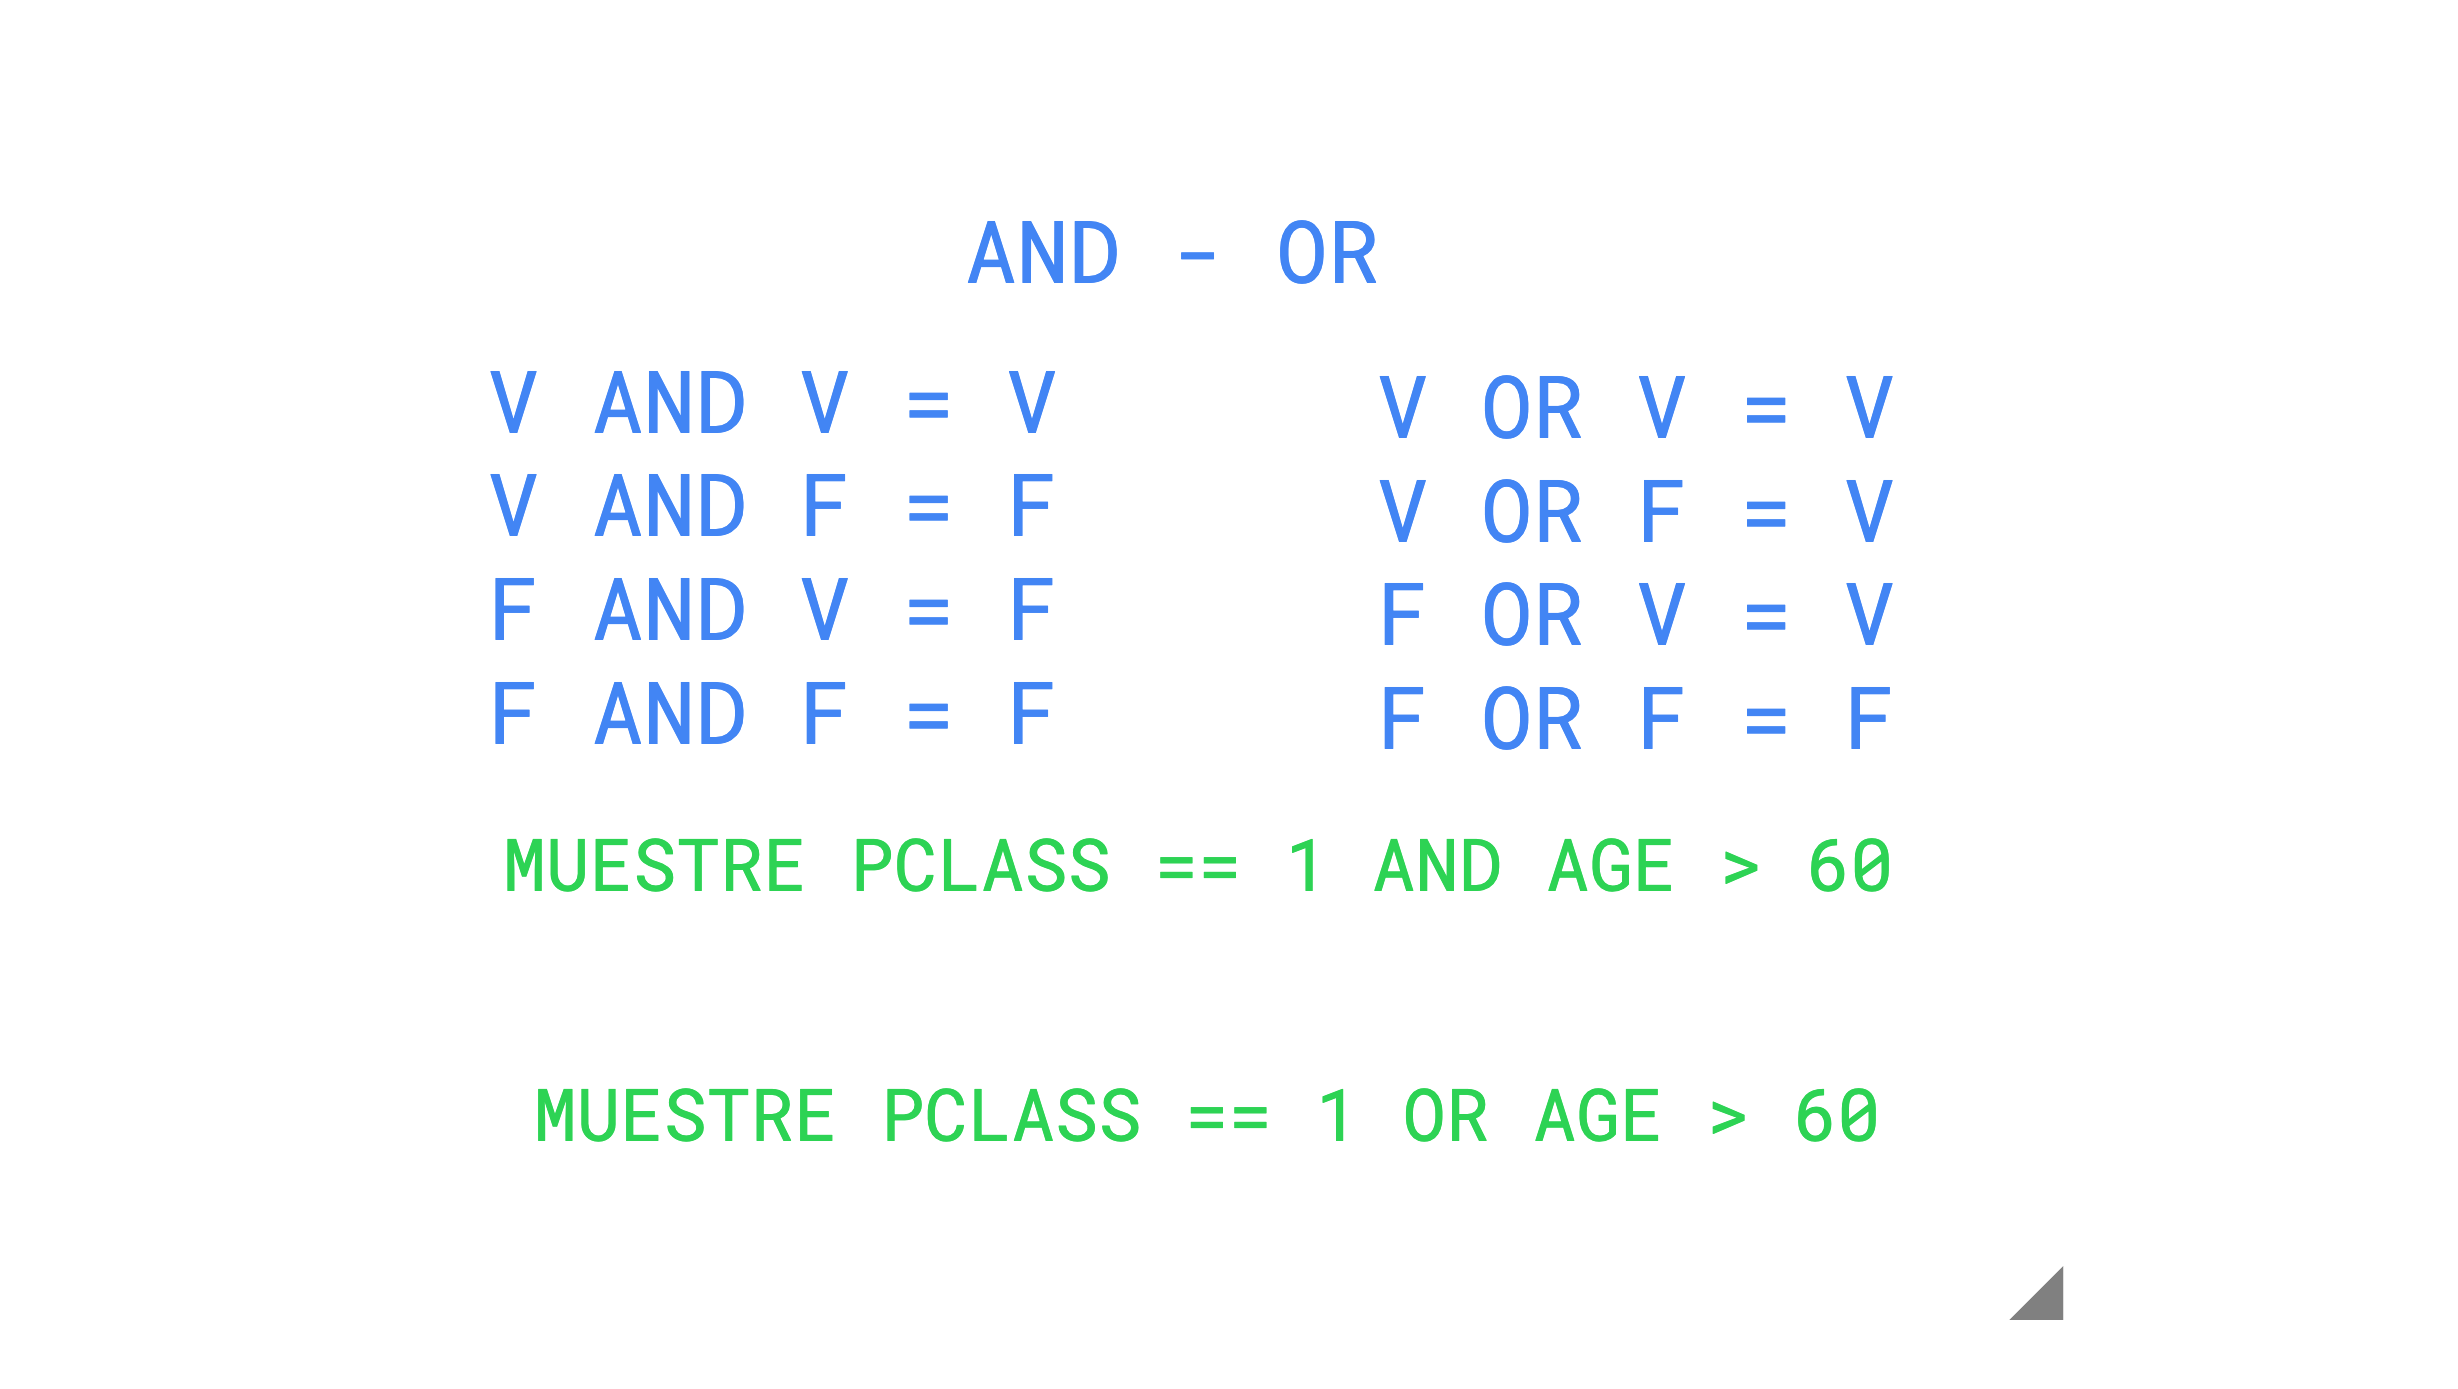

**Regla importante para filtrar:** cada condición va entre paréntesis y se combinan con `&` (y), `|` (o) y `~` (negación). No se usan `and` ni `or` de Python.

## 2.5 Crear y transformar columnas

Las operaciones entre columnas son vectorizadas, igual que en NumPy.

In [ ]:
titanic["es_menor"] = titanic["age"] < 18
titanic["tarifa_clp"] = titanic["fare"] * 1000     # conversión inventada, solo de ejemplo
titanic[["age", "es_menor", "fare", "tarifa_clp"]].head(11)

,age,es_menor,fare,tarifa_clp
0,22.0,False,7.2500,7250.0
1,38.0,False,71.2833,71283.3
2,26.0,False,7.9250,7925.0
3,35.0,False,53.1000,53100.0
4,35.0,False,8.0500,8050.0
5,NaN,False,8.4583,8458.3
6,54.0,False,51.8625,51862.5
7,2.0,True,21.0750,21075.0
8,27.0,False,11.1333,11133.3
9,14.0,True,30.0708,30070.8


In [ ]:
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,es_menor,tarifa_clp
0,0,3,male,22.0,1,0,7.2500,S,False,7250.0
1,1,1,female,38.0,1,0,71.2833,C,False,71283.3
2,1,3,female,26.0,0,0,7.9250,S,False,7925.0
3,1,1,female,35.0,1,0,53.1000,S,False,53100.0
4,0,3,male,35.0,0,0,8.0500,S,False,8050.0
...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,False,13000.0
887,1,1,female,19.0,0,0,30.0000,S,False,30000.0
888,0,3,female,NaN,1,2,23.4500,S,False,23450.0
889,1,1,male,26.0,0,0,30.0000,C,False,30000.0


In [ ]:
# map: reemplazar valores según un diccionario
titanic["puerto"] = titanic["embarked"].map({"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"})
titanic["puerto"].value_counts()

,count
puerto,
Southampton,644
Cherbourg,168
Queenstown,77


In [ ]:
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,es_menor,tarifa_clp,puerto
0,0,3,male,22.0,1,0,7.2500,S,False,7250.0,Southampton
1,1,1,female,38.0,1,0,71.2833,C,False,71283.3,Cherbourg
2,1,3,female,26.0,0,0,7.9250,S,False,7925.0,Southampton
3,1,1,female,35.0,1,0,53.1000,S,False,53100.0,Southampton
4,0,3,male,35.0,0,0,8.0500,S,False,8050.0,Southampton
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,False,13000.0,Southampton
887,1,1,female,19.0,0,0,30.0000,S,False,30000.0,Southampton
888,0,3,female,NaN,1,2,23.4500,S,False,23450.0,Southampton
889,1,1,male,26.0,0,0,30.0000,C,False,30000.0,Cherbourg


## 2.6 Agrupar y resumir con `groupby`

`groupby` responde preguntas del tipo "¿cuál es el promedio de X **para cada** grupo de Y?". Funciona en tres pasos: separa los datos por grupo, aplica una función a cada grupo y junta los resultados.

In [ ]:
# Tasa de supervivencia por sexo
titanic.groupby("sex")["survived"].mean().round(3)

,survived
sex,
female,0.742
male,0.189


In [ ]:
# Varias métricas a la vez
titanic.groupby("pclass").agg(
    pasajeros=("survived", "size"),
    tasa_supervivencia=("survived", "mean"),
    tarifa_promedio=("fare", "mean"),
    edad_mediana=("age", "median"),
).round(2)

,pasajeros,tasa_supervivencia,tarifa_promedio,edad_mediana
pclass,,,,
1,216,0.63,84.15,37.0
2,184,0.47,20.66,29.0
3,491,0.24,13.68,24.0


In [ ]:
# Tabla cruzada: sexo x clase
pd.pivot_table(titanic, values="survived", index="sex", columns="pclass", aggfunc="mean").round(2)

pclass,1,2,3
sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


## 2.7 Valores faltantes

La columna `age` tiene 177 valores faltantes (`NaN`). Hay tres estrategias comunes:

1. **Eliminar** las filas incompletas con `dropna()`. Simple, pero se pierden datos.
2. **Rellenar** con un valor fijo, como la mediana, usando `fillna()`.
3. **Rellenar por grupo**, por ejemplo con la mediana de su clase. Suele ser más preciso.

La mediana es mejor que el promedio cuando hay valores extremos.

In [ ]:
print("Filas antes:", len(titanic), "| sin faltantes en age:", len(titanic.dropna(subset=["age"])))

mediana_edad = titanic["age"].median()
edad_rellena = titanic["age"].fillna(mediana_edad)
print("Faltantes después de rellenar:", edad_rellena.isna().sum())

Filas antes: 891 | sin faltantes en age: 714
Faltantes después de rellenar: 0


In [ ]:
titanic.describe()

,survived,pclass,age,sibsp,parch,fare,tarifa_clp
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208,32204.207969
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429,49693.428597
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400,7910.400000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200,14454.200000
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000,31000.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,512329.200000


## 2.8 Visualizar

pandas y seaborn permiten graficar con muy poco código. Un gráfico bien elegido muestra en segundos lo que una tabla esconde.

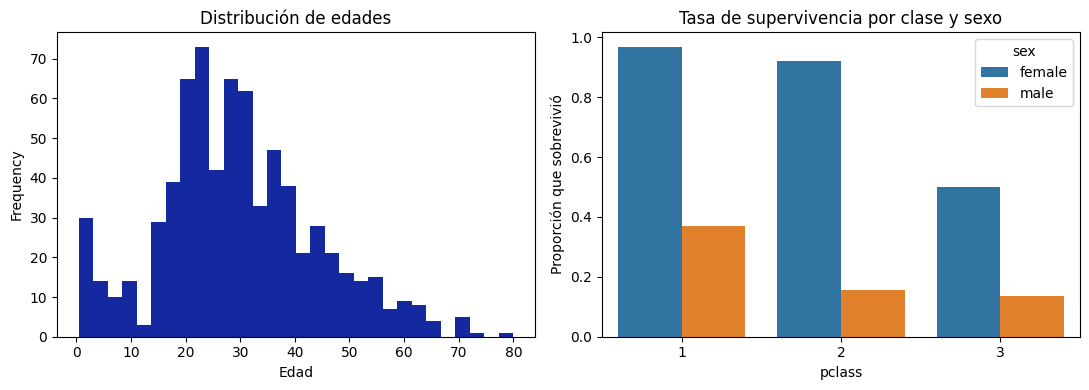

In [ ]:
import matplotlib.pyplot as plt


fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

titanic["age"].plot(kind="hist", bins=30, ax=ejes[0], color="#1428A0")
ejes[0].set_title("Distribución de edades")
ejes[0].set_xlabel("Edad")

sns.barplot(data=titanic, x="pclass", y="survived", hue="sex", ax=ejes[1], errorbar=None)
ejes[1].set_title("Tasa de supervivencia por clase y sexo")
ejes[1].set_ylabel("Proporción que sobrevivió")

plt.tight_layout()
plt.show()

# Tutorial de visualización con Matplotlib y Seaborn

## ¿Qué son y en qué se diferencian?

| | Matplotlib | Seaborn |
|---|---|---|
| ¿Qué es? | La librería base de gráficos en Python | Una librería construida **sobre** Matplotlib |
| Nivel | Bajo nivel: controlas cada detalle | Alto nivel: gráficos estadísticos con poco código |
| Datos | Trabaja con listas y arrays | Trabaja muy bien con `DataFrame` de pandas |
| Ideal para | Personalizar completamente un gráfico | Explorar datos rápidamente |

> **Idea clave:** Seaborn dibuja usando Matplotlib. Por eso puedes crear un gráfico con Seaborn y luego ajustarlo con funciones de Matplotlib.

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
```

Por convención se usan los alias `plt` y `sns`.

---

# Parte 1: Matplotlib

## 1.1 Anatomía de un gráfico

En Matplotlib hay dos conceptos fundamentales:

- **Figure (`fig`):** la "hoja" completa donde se dibuja.
- **Axes (`ax`):** cada gráfico individual dentro de la figura, con sus ejes, título y datos.

```
┌─────────────── Figure ───────────────┐
│  ┌──────── Axes ────────┐            │
│  │  Título              │            │
│  │  y ┃    ╱╲    ╱      │            │
│  │    ┃   ╱  ╲  ╱       │            │
│  │    ┗━━━━━━━━━━━ x    │            │
│  └──────────────────────┘            │
└──────────────────────────────────────┘
```

## 1.2 Dos formas de usar Matplotlib

**Forma rápida (`pyplot`):** útil para gráficos simples.

```python
x = [1, 2, 3, 4, 5]
y = [2, 4, 1, 5, 3]

plt.plot(x, y)
plt.title("Mi primer gráfico")
plt.show()
```

**Forma orientada a objetos (recomendada):** más clara cuando hay varios gráficos.

```python
fig, ax = plt.subplots()
ax.plot(x, y)
ax.set_title("Mi primer gráfico")
plt.show()
```

> Recomendación: acostúmbrate a la forma `fig, ax = plt.subplots()`. Es la que se usa en la mayoría de la documentación y en proyectos reales.

## 1.3 Gráfico de líneas

Ideal para mostrar **cambios a lo largo del tiempo** o de una variable continua.

```python
x = np.linspace(0, 10, 100)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, np.sin(x), label="seno", color="tab:blue", linewidth=2)
ax.plot(x, np.cos(x), label="coseno", color="tab:orange", linestyle="--")

ax.set_title("Funciones trigonométricas")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
```

| Parámetro | Ejemplos de valores |
|---|---|
| `color` | `"red"`, `"tab:blue"`, `"#1f77b4"` |
| `linestyle` | `"-"`, `"--"`, `":"`, `"-."` |
| `linewidth` | `1`, `2`, `3` |
| `marker` | `"o"`, `"s"`, `"^"`, `"x"` |

## 1.4 Gráfico de dispersión

Ideal para ver la **relación entre dos variables numéricas**.

```python
rng = np.random.default_rng(42)
horas_estudio = rng.uniform(0, 10, 50)
nota = 1 + 0.5 * horas_estudio + rng.normal(0, 0.6, 50)

fig, ax = plt.subplots()
ax.scatter(horas_estudio, nota, alpha=0.7, edgecolor="black")
ax.set(title="Horas de estudio vs. nota",
       xlabel="Horas de estudio", ylabel="Nota")
plt.show()
```

> `ax.set(...)` permite definir título y etiquetas en una sola línea.

## 1.5 Gráfico de barras

Ideal para **comparar categorías**.

```python
lenguajes = ["Python", "JavaScript", "Java", "C++"]
estudiantes = [45, 30, 15, 10]

fig, ax = plt.subplots()
barras = ax.bar(lenguajes, estudiantes, color="tab:green")
ax.bar_label(barras)          # muestra el valor sobre cada barra
ax.set(title="Lenguaje favorito del curso", ylabel="Estudiantes")
plt.show()
```

Para barras horizontales, usa `ax.barh(...)`, útil cuando los nombres de las categorías son largos.

## 1.6 Histograma

Ideal para ver la **distribución** de una variable numérica.

```python
notas = rng.normal(5.0, 1.0, 200).clip(1, 7)

fig, ax = plt.subplots()
ax.hist(notas, bins=15, edgecolor="black")
ax.axvline(4.0, color="red", linestyle="--", label="Nota mínima de aprobación")
ax.set(title="Distribución de notas", xlabel="Nota", ylabel="Frecuencia")
ax.legend()
plt.show()
```

## 1.7 Varios gráficos en una figura

```python
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

axes[0].plot(x, np.sin(x))
axes[0].set_title("Líneas")

axes[1].scatter(horas_estudio, nota)
axes[1].set_title("Dispersión")

axes[2].hist(notas, bins=15)
axes[2].set_title("Histograma")

fig.suptitle("Tres tipos de gráficos", fontsize=14)
fig.tight_layout()     # evita que los textos se superpongan
plt.show()
```

Con `plt.subplots(2, 2)`, `axes` es una matriz y se accede como `axes[0, 1]`.

## 1.8 Guardar un gráfico

```python
fig.savefig("grafico.png", dpi=300, bbox_inches="tight")
```

- `dpi=300`: alta resolución, adecuada para informes e impresión.
- `bbox_inches="tight"`: recorta los bordes blancos sobrantes.
- También puedes guardar como `.pdf` o `.svg` (formato vectorial, ideal para LaTeX).

> ⚠️ Llama a `savefig` **antes** de `plt.show()`: después de mostrarse, la figura puede quedar vacía.

En Colab, el archivo queda en el panel de archivos de la izquierda. Para descargarlo:

```python
from google.colab import files
files.download("grafico.png")
```

---

# Parte 2: Seaborn

## 2.1 Datos de ejemplo

Seaborn incluye conjuntos de datos para practicar:

```python
tips = sns.load_dataset("tips")          # propinas en un restaurante
penguins = sns.load_dataset("penguins")  # medidas de pingüinos

tips.head()
```

| Columna de `tips` | Descripción |
|---|---|
| `total_bill` | Total de la cuenta |
| `tip` | Propina |
| `sex`, `smoker` | Sexo y si es fumador |
| `day`, `time` | Día y momento (almuerzo o cena) |
| `size` | Número de personas en la mesa |

## 2.2 Temas visuales

```python
sns.set_theme(style="whitegrid")   # aplica un estilo a todos los gráficos siguientes
```

Estilos disponibles: `"darkgrid"`, `"whitegrid"`, `"dark"`, `"white"`, `"ticks"`.

## 2.3 La lógica de Seaborn: `data`, `x`, `y`, `hue`

Casi todas las funciones de Seaborn siguen el mismo patrón:

```python
sns.funcion(data=dataframe, x="columna_x", y="columna_y", hue="columna_color")
```

- `data`: el `DataFrame`.
- `x`, `y`: **nombres de columnas** (como texto).
- `hue`: columna que define el **color**, para separar grupos.

```python
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time")
plt.show()
```

Con una sola línea obtenemos colores por grupo y leyenda automática. En Matplotlib puro esto requeriría un ciclo.

## 2.4 Distribuciones

```python
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(data=tips, x="total_bill", kde=True, ax=axes[0])
axes[0].set_title("Histograma con curva de densidad")

sns.histplot(data=tips, x="total_bill", hue="time", element="step", ax=axes[1])
axes[1].set_title("Comparación por momento del día")

fig.tight_layout()
plt.show()
```

`kde=True` agrega una curva suave que estima la forma de la distribución.

## 2.5 Comparar categorías

```python
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=tips, x="day", y="total_bill", ax=axes[0])
axes[0].set_title("Promedio (barplot)")

sns.boxplot(data=tips, x="day", y="total_bill", hue="smoker", ax=axes[1])
axes[1].set_title("Distribución (boxplot)")

sns.violinplot(data=tips, x="day", y="total_bill", ax=axes[2])
axes[2].set_title("Forma de la distribución (violinplot)")

fig.tight_layout()
plt.show()
```

| Gráfico | Qué muestra |
|---|---|
| `barplot` | El **promedio** de cada grupo y una barra de error (intervalo de confianza del 95 %) |
| `boxplot` | Mediana, cuartiles y valores atípicos |
| `violinplot` | La forma completa de la distribución |
| `countplot` | Cuántas filas hay en cada categoría |

> ⚠️ Un `barplot` de Seaborn **no muestra la suma**, sino el promedio. Es un error común de interpretación.

## 2.6 Relaciones y tendencias

**Línea de regresión:**

```python
sns.regplot(data=tips, x="total_bill", y="tip")
plt.title("¿La propina aumenta con la cuenta?")
plt.show()
```

**Líneas con intervalo de confianza:**

```python
fmri = sns.load_dataset("fmri")
sns.lineplot(data=fmri, x="timepoint", y="signal", hue="event")
plt.show()
```

Cuando hay varias observaciones por cada valor de `x`, `lineplot` dibuja el promedio y una banda sombreada con su intervalo de confianza.

## 2.7 Mapa de calor de correlaciones

```python
correlaciones = penguins.select_dtypes("number").corr()

sns.heatmap(correlaciones, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre medidas de pingüinos")
plt.show()
```

- `annot=True`: escribe el valor en cada celda.
- `vmin=-1, vmax=1`: fija la escala para que el color 0 sea neutro.

## 2.8 Explorar todo un conjunto de datos: `pairplot`

```python
sns.pairplot(penguins, hue="species")
plt.show()
```

Crea una matriz con la dispersión de cada par de variables numéricas y la distribución de cada una. Es una de las mejores formas de **iniciar un análisis exploratorio**.

## 2.9 Gráficos por paneles (*facets*)

```python
sns.relplot(data=tips, x="total_bill", y="tip",
            hue="smoker", col="time", kind="scatter")
plt.show()
```

`col="time"` crea un panel por cada valor de la columna `time`. También existe `row=` para dividir por filas.

### Funciones *axes-level* vs. *figure-level*

| Tipo | Ejemplos | Características |
|---|---|---|
| **Axes-level** | `scatterplot`, `histplot`, `boxplot`, `heatmap` | Dibujan en un `ax`; aceptan `ax=` |
| **Figure-level** | `relplot`, `displot`, `catplot`, `pairplot` | Crean su propia figura; permiten `col=` y `row=`, pero **no** aceptan `ax=` |

> Si quieres poner un gráfico de Seaborn dentro de un `plt.subplots()`, usa funciones *axes-level*.

---

# Parte 3: Combinar Matplotlib y Seaborn

Las funciones *axes-level* de Seaborn devuelven un objeto `ax` de Matplotlib, que puedes seguir personalizando:

```python
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="species", s=60, ax=ax)

ax.set(title="Longitud de aleta vs. masa corporal",
       xlabel="Longitud de aleta (mm)",
       ylabel="Masa corporal (g)")
ax.legend(title="Especie", loc="upper left")
ax.axhline(penguins["body_mass_g"].mean(), color="gray",
           linestyle=":", label="Promedio")

fig.tight_layout()
fig.savefig("pinguinos.png", dpi=300, bbox_inches="tight")
plt.show()
```

**Flujo de trabajo recomendado:**

1. Crea la figura con Matplotlib: `fig, ax = plt.subplots()`.
2. Dibuja los datos con Seaborn: `sns.funcion(..., ax=ax)`.
3. Ajusta títulos, etiquetas y detalles con Matplotlib: `ax.set(...)`.
4. Guarda con `fig.savefig(...)`.

---

# Parte 4: ¿Qué gráfico usar?

| Quiero mostrar... | Gráfico | Matplotlib | Seaborn |
|---|---|---|---|
| Evolución en el tiempo | Líneas | `ax.plot` | `sns.lineplot` |
| Relación entre dos variables | Dispersión | `ax.scatter` | `sns.scatterplot` |
| Comparación entre categorías | Barras | `ax.bar` | `sns.barplot`, `sns.countplot` |
| Distribución de una variable | Histograma | `ax.hist` | `sns.histplot` |
| Distribución por grupos | Caja o violín | `ax.boxplot` | `sns.boxplot`, `sns.violinplot` |
| Correlaciones | Mapa de calor | `ax.imshow` | `sns.heatmap` |
| Exploración general | Matriz de gráficos | — | `sns.pairplot` |

## Buenas prácticas

- ✅ Todo gráfico necesita **título** y **etiquetas en los ejes**, con unidades cuando corresponda.
- ✅ Usa colores con significado; evita colores decorativos.
- ✅ Prefiere paletas aptas para daltonismo, como `sns.color_palette("colorblind")`.
- ✅ No uses gráficos de torta para comparar muchas categorías: las barras se leen mejor.
- ✅ Revisa si el eje Y empieza en cero en gráficos de barras; si no, las diferencias pueden parecer exageradas.

---

## Para practicar

1. Con el conjunto `tips`, crea un gráfico de barras con Matplotlib que muestre cuántas mesas hubo cada día. Luego haz lo mismo con `sns.countplot`. ¿Cuál requirió menos código?
2. Crea una figura de 2x2 con cuatro gráficos distintos del conjunto `penguins`.
3. Usa `sns.boxplot` para comparar la masa corporal (`body_mass_g`) de cada especie, separando por sexo con `hue`.
4. Crea un `heatmap` de correlaciones del conjunto `tips`. ¿Qué variables están más relacionadas con la propina?
5. Toma uno de tus gráficos de Seaborn, cambia su título y etiquetas con Matplotlib, y guárdalo en formato PDF.

## Fuentes

- [Matplotlib: Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html)
- [Matplotlib: Plot types](https://matplotlib.org/stable/plot_types/index.html)
- [Seaborn: An introduction to seaborn](https://seaborn.pydata.org/tutorial/introduction.html)
- [Seaborn: Example gallery](https://seaborn.pydata.org/examples/index.html)

## Ejercicios de pandas

### Ejercicio 4
Crea `tasa_por_puerto`: una Series con la tasa de supervivencia de cada puerto de embarque (columna `embarked`), ordenada de mayor a menor.

In [ ]:
tasa_por_puerto = None  # TU CÓDIGO AQUÍ
tasa_por_puerto

In [ ]:
_esperado = titanic.groupby("embarked")["survived"].mean().sort_values(ascending=False)
revisar(lambda: list(tasa_por_puerto.index) == list(_esperado.index) and np.allclose(tasa_por_puerto.values, _esperado.values))

### Ejercicio 5
1. Crea la columna `familia` en `titanic`: el tamaño del grupo familiar a bordo, es decir `sibsp + parch + 1` (el 1 es el propio pasajero).
2. Crea la columna `viaja_solo`, que sea `True` cuando `familia` vale 1.
3. Crea `tasa_solo`: la tasa de supervivencia de quienes viajaban solos y de quienes no (agrupando por `viaja_solo`).

In [ ]:
# TU CÓDIGO AQUÍ


tasa_solo = None
tasa_solo

In [ ]:
revisar(lambda: (titanic["familia"] == titanic["sibsp"] + titanic["parch"] + 1).all()
               and (titanic["viaja_solo"] == (titanic["familia"] == 1)).all()
               and np.isclose(tasa_solo[True], titanic.loc[titanic["familia"] == 1, "survived"].mean()))

### Ejercicio 6
Rellena los valores faltantes de `age` con la **mediana de edad de la clase** (`pclass`) de cada pasajero y guarda el resultado en la columna `age` de `titanic`.

Pista: `titanic.groupby("pclass")["age"].transform("median")` devuelve, para cada fila, la mediana de su clase.

In [ ]:
# TU CÓDIGO AQUÍ

print("Faltantes en age:", titanic["age"].isna().sum())

In [ ]:
_orig = sns.load_dataset("titanic")
_med = _orig.groupby("pclass")["age"].transform("median")
revisar(lambda: titanic["age"].isna().sum() == 0 and np.allclose(titanic["age"], _orig["age"].fillna(_med)))

### Ejercicio 7 (análisis)
Usando `groupby` o `pivot_table`, responde: **¿qué grupo tuvo la tasa de supervivencia más baja: hombres de qué clase?** Escribe el código y anota tu conclusión en la celda de texto siguiente.

In [ ]:
# TU CÓDIGO AQUÍ

**Mi conclusión:** (escribe aquí con doble clic)

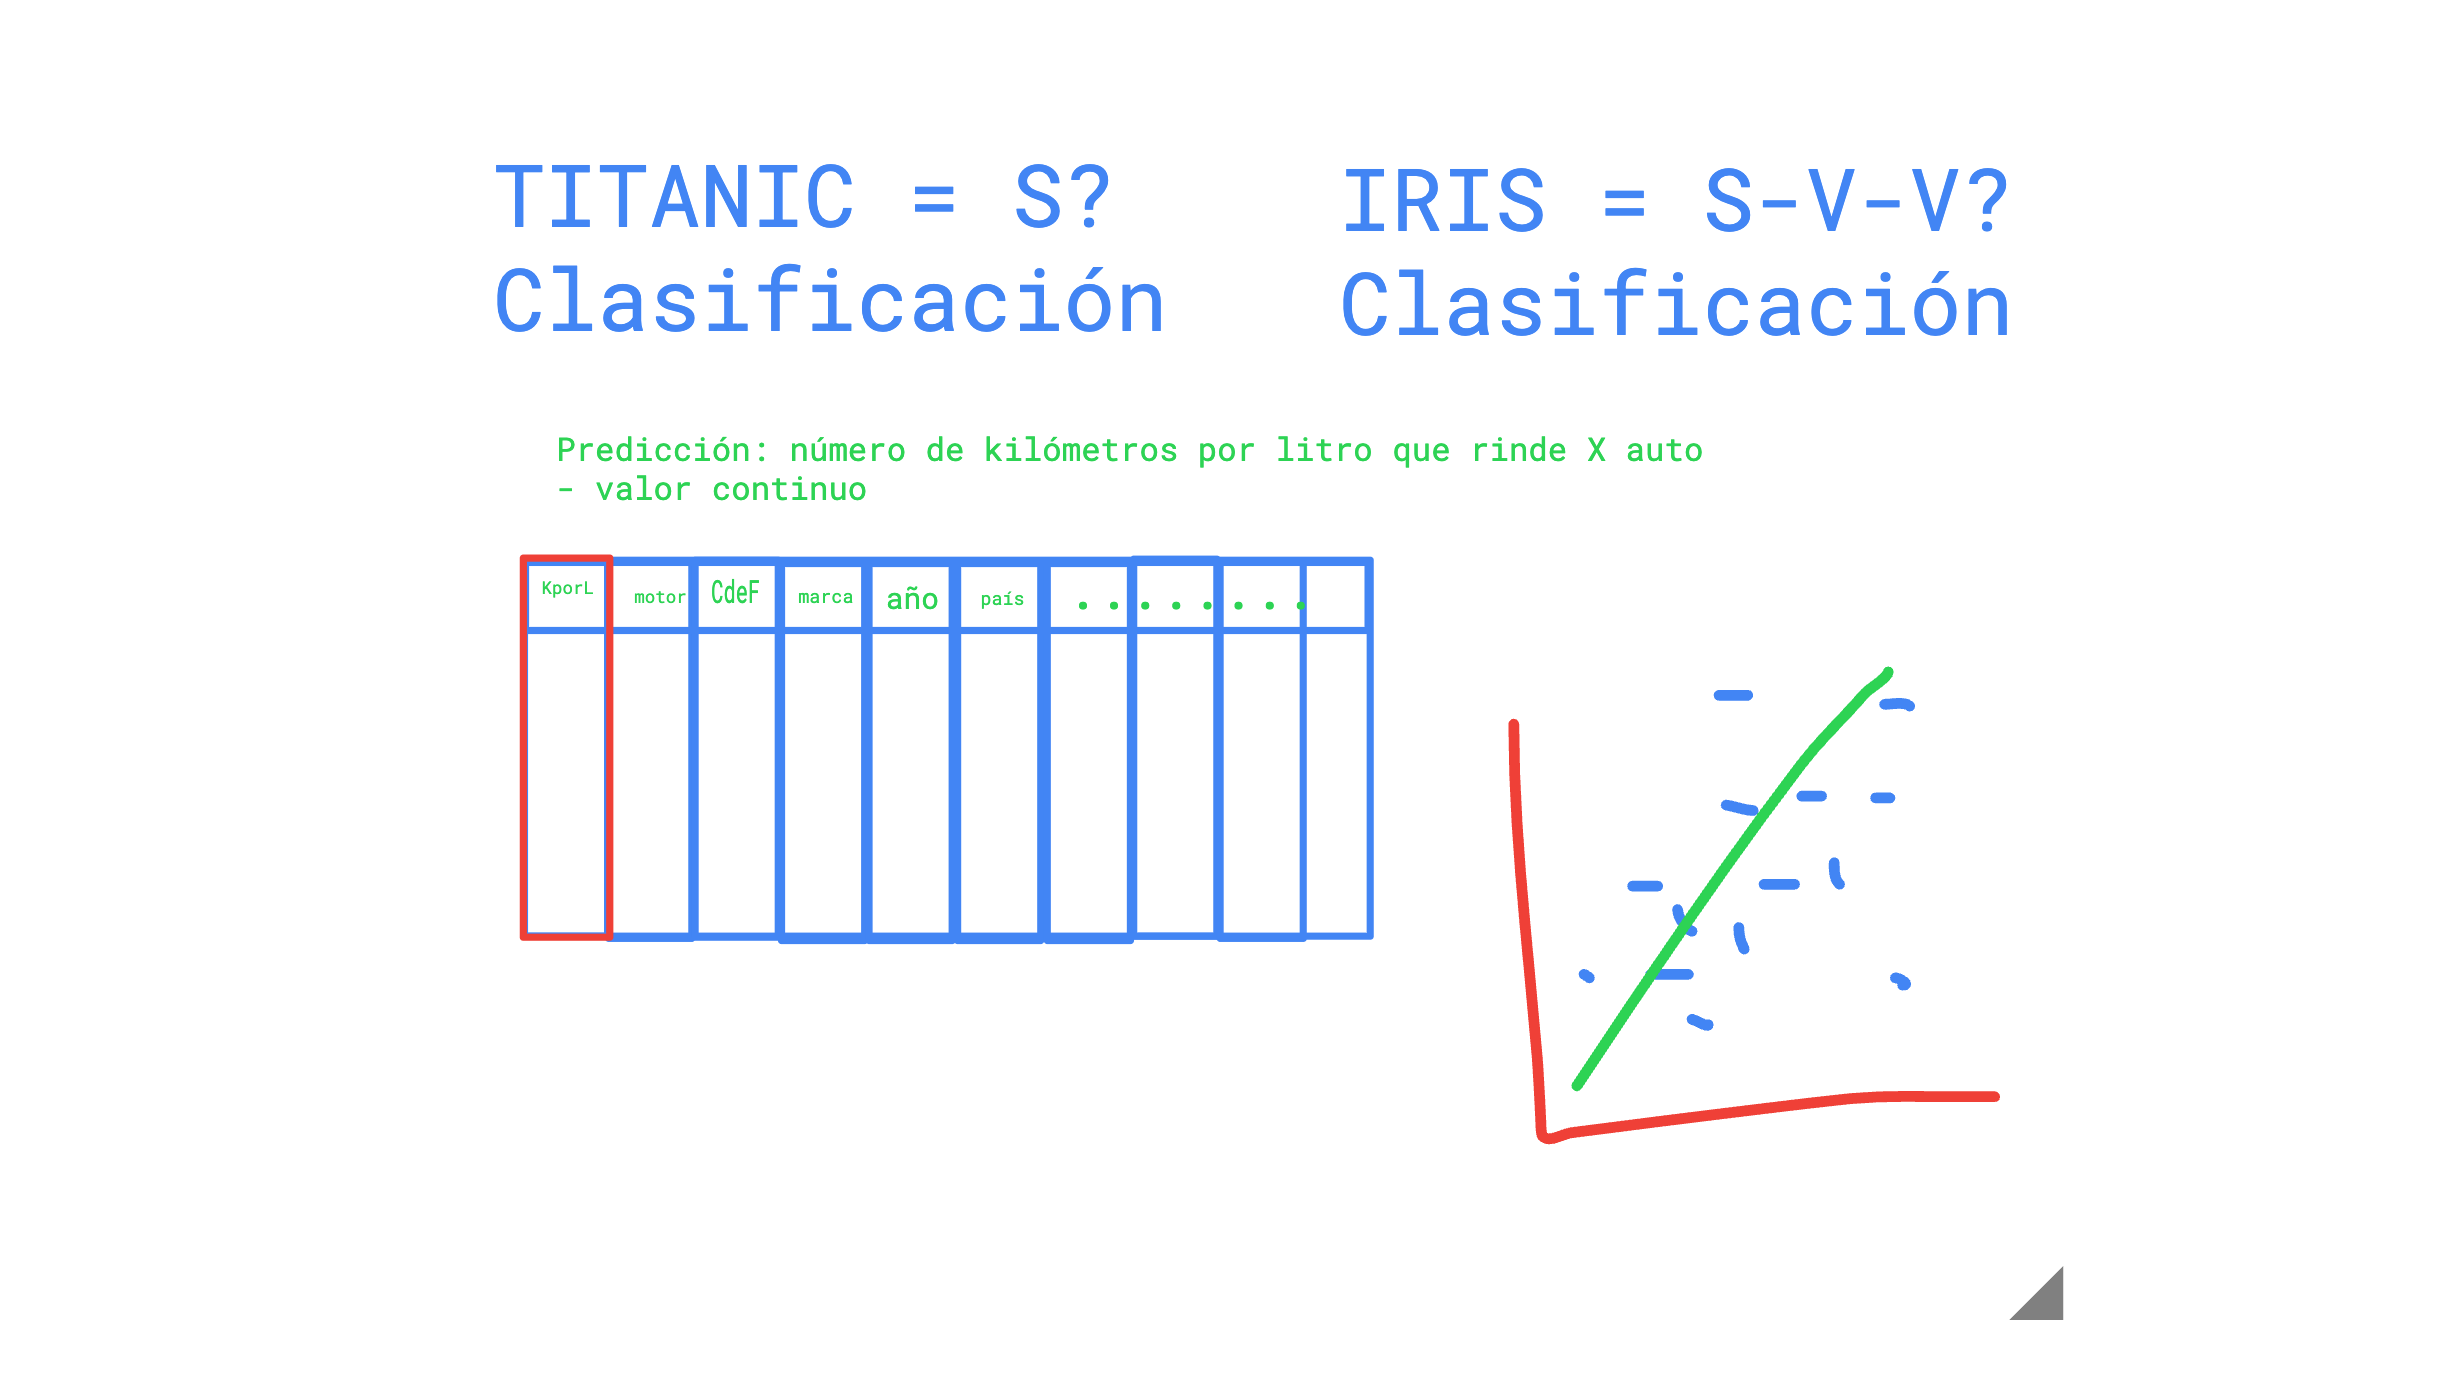

![](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSlLkryKaqVZRbafJKkcxArvnDFiag9U6BVQmrfMdbvLA&s=10)

In [ ]:
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,es_menor,tarifa_clp,puerto
0,0,3,male,22.0,1,0,7.2500,S,False,7250.0,Southampton
1,1,1,female,38.0,1,0,71.2833,C,False,71283.3,Cherbourg
2,1,3,female,26.0,0,0,7.9250,S,False,7925.0,Southampton
3,1,1,female,35.0,1,0,53.1000,S,False,53100.0,Southampton
4,0,3,male,35.0,0,0,8.0500,S,False,8050.0,Southampton
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,False,13000.0,Southampton
887,1,1,female,19.0,0,0,30.0000,S,False,30000.0,Southampton
888,0,3,female,NaN,1,2,23.4500,S,False,23450.0,Southampton
889,1,1,male,26.0,0,0,30.0000,C,False,30000.0,Cherbourg


---
# Variables categóricas en Machine Learning: cómo codificarlas correctamente

## 1. El problema: ¿el número es una magnitud o una etiqueta?

Los modelos de Machine Learning solo trabajan con números. Por eso, cuando un conjunto de datos tiene categorías como "Sedán", "Camioneta" y "Motocicleta", es tentador reemplazarlas por 1, 2 y 3. El problema es que **un número trae consigo propiedades matemáticas** que una etiqueta no tiene:

| Propiedad del número | Lo que el modelo asume | ¿Tiene sentido para los vehículos? |
|---|---|---|
| Orden | 1 < 2 < 3 | No: una camioneta no es "mayor" que un sedán |
| Distancia | De 1 a 3 hay el doble de distancia que de 1 a 2 | No: la moto no está "el doble de lejos" del sedán |
| Promedio | El promedio de 1 y 3 es 2 | No: el promedio de un sedán y una moto no es una camioneta |

En otras palabras, al usar 1, 2 y 3 le estamos **inventando información al modelo**. La pregunta clave antes de codificar es siempre la misma: **¿este número representa una cantidad o solo un nombre?**

---

## 2. Primero: ¿la categoría es una entrada o el objetivo?

Esta distinción cambia completamente la respuesta.

### Si la categoría es el objetivo (lo que se quiere predecir)

En un problema de **clasificación**, codificar las clases como 0, 1, 2 **no es un problema**. El modelo no las trata como magnitudes, sino como identificadores de clase: una regresión logística multiclase, por ejemplo, calcula una probabilidad separada para cada una.

```python
from sklearn.preprocessing import LabelEncoder

y = ["Sedán", "Moto", "Camioneta", "Sedán"]
y_codificado = LabelEncoder().fit_transform(y)
print(y_codificado)   # [2 1 0 2]
```

> El único error sería tratar ese objetivo como un problema de **regresión** (predecir un valor continuo), porque entonces un resultado como 1,5 se interpretaría como "algo entre moto y sedán".

### Si la categoría es una entrada (feature)

Aquí sí aparece el problema descrito en la sección 1, y la codificación debe elegirse con cuidado. El resto de este documento se refiere a este caso.

---

## 3. Una demostración concreta

Supongamos que queremos predecir el precio (en millones) según el tipo de vehículo:

| Tipo | Código | Precio |
|---|---|---|
| Sedán | 1 | 20 |
| Camioneta | 2 | 35 |
| Moto | 3 | 8 |

```python
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

df = pd.DataFrame({
    "tipo": ["Sedán", "Camioneta", "Moto"],
    "precio": [20, 35, 8]
})

# Opción incorrecta: códigos 1, 2, 3
X_codigos = np.array([[1], [2], [3]])
modelo = LinearRegression().fit(X_codigos, df["precio"])
print(modelo.predict(X_codigos))      # [27. 21. 15.]

# Opción correcta: One-Hot Encoding
X_onehot = pd.get_dummies(df["tipo"])
modelo = LinearRegression().fit(X_onehot, df["precio"])
print(modelo.predict(X_onehot))       # [20. 35.  8.]
```

Con los códigos 1, 2, 3 el modelo lineal está **obligado** a suponer que el precio sube o baja en la misma cantidad cada vez que el código aumenta en 1. Como la camioneta (código 2) es la más cara, ninguna recta puede representar los datos, y las predicciones fallan incluso en los mismos datos de entrenamiento. Con One-Hot Encoding cada tipo tiene su propio coeficiente y el problema desaparece.

---

## 4. Tipos de variables categóricas

| Tipo | Definición | Ejemplos | Codificación habitual |
|---|---|---|---|
| **Nominal** | No existe un orden lógico entre las categorías | Color, tipo de vehículo, comuna, especie | One-Hot Encoding |
| **Ordinal** | Existe un orden natural | Bajo / Medio / Alto; Básica / Media / Universitaria | Ordinal Encoding, respetando el orden |

### Una advertencia sobre las variables ordinales

Codificar "Bajo, Medio, Alto" como 0, 1, 2 respeta el orden, pero **también asume que los saltos son iguales**: que pasar de Bajo a Medio equivale a pasar de Medio a Alto. Esto puede no ser cierto. Por ejemplo, la diferencia de ingresos entre educación media y universitaria no tiene por qué ser igual a la diferencia entre básica y media.

- En **modelos de árboles**, esto no importa: solo usan el orden.
- En **modelos lineales**, si los saltos son muy desiguales, One-Hot Encoding puede funcionar mejor aunque la variable sea ordinal.

---

## 5. Técnicas de codificación

### 5.1 One-Hot Encoding

Crea una columna binaria (0 o 1) por cada categoría. A estas columnas se les llama **variables indicadoras** o *dummies*.

| tipo | tipo_Camioneta | tipo_Moto | tipo_Sedán |
|---|---|---|---|
| Sedán | 0 | 0 | 1 |
| Camioneta | 1 | 0 | 0 |
| Moto | 0 | 1 | 0 |

Una propiedad importante: con esta codificación, **todas las categorías quedan a la misma distancia entre sí** (raíz de 2 en distancia euclidiana). Por eso es la opción natural para modelos basados en distancias, como KNN.

```python
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoder.fit(df[["tipo"]])
print(encoder.transform(df[["tipo"]]))
print(encoder.get_feature_names_out())
```

**Limitaciones:**

- **Alta cardinalidad:** una variable con 300 comunas genera 300 columnas.
- **Colinealidad perfecta (trampa de las *dummies*):** en modelos lineales con intercepto, la última columna siempre se puede deducir de las demás. Si se necesitan coeficientes interpretables (por ejemplo, en un análisis estadístico), se elimina una columna con `drop="first"`, y esa categoría pasa a ser la referencia. Con regularización (como en la configuración por defecto de `LogisticRegression`) esto suele no ser necesario.

### 5.2 Ordinal Encoding

Asigna un entero a cada categoría **en el orden que tú indiques**.

```python
from sklearn.preprocessing import OrdinalEncoder

niveles = pd.DataFrame({"nivel": ["Medio", "Bajo", "Alto", "Medio"]})

encoder = OrdinalEncoder(categories=[["Bajo", "Medio", "Alto"]])
print(encoder.fit_transform(niveles))   # [[1.] [0.] [2.] [1.]]
```

> Si no se entrega el parámetro `categories`, el orden será **alfabético** (Alto = 0, Bajo = 1, Medio = 2), lo que destruye el orden real. Es un error frecuente.

### 5.3 Target Encoding

Reemplaza cada categoría por un resumen del objetivo en esa categoría, por ejemplo, el precio promedio de cada tipo de vehículo. Es útil cuando hay **muchas categorías**.

```python
from sklearn.preprocessing import TargetEncoder   # scikit-learn 1.3 o superior

encoder = TargetEncoder(target_type="continuous")
X_te = encoder.fit_transform(X_train[["comuna"]], y_train)
```

**Riesgo principal: fuga de información (*data leakage*).** Si se calcula el promedio del objetivo usando la misma fila que luego se usa para entrenar, el modelo "ve" parte de la respuesta y su rendimiento en entrenamiento será engañosamente alto. El `TargetEncoder` de scikit-learn mitiga esto con validación cruzada interna al usar `fit_transform`, y además suaviza los promedios de categorías con pocos datos.

### 5.4 Otras alternativas

| Técnica | Idea | Cuándo considerarla |
|---|---|---|
| Frequency Encoding | Reemplazar cada categoría por su frecuencia | Muchas categorías, cuando la frecuencia es informativa |
| Hashing | Asignar categorías a un número fijo de columnas mediante una función hash | Cardinalidad muy alta o categorías que cambian con el tiempo |
| Embeddings | El modelo aprende un vector denso para cada categoría | Redes neuronales con muchas categorías (usuarios, productos, palabras) |

---

## 6. ¿Cómo afecta la codificación a cada tipo de modelo?

| Familia de modelos | Ejemplos | ¿Qué pasa con códigos 1, 2, 3 en una variable nominal? | Recomendación |
|---|---|---|---|
| **Lineales** | Regresión lineal, regresión logística, SVM lineal | Asumen un efecto proporcional al código: cada aumento de 1 suma lo mismo a la predicción | One-Hot Encoding; Target Encoding si hay muchas categorías |
| **Basados en distancias** | KNN, K-Means, SVM con kernel RBF | Calculan distancias falsas: la categoría 1 queda "más cerca" de la 2 que de la 3 | One-Hot Encoding |
| **Redes neuronales** | MLP, redes profundas | Mismo problema que los modelos lineales en la primera capa | One-Hot si hay pocas categorías; embeddings si hay muchas |
| **Árboles y ensambles** | Árbol de decisión, Random Forest, XGBoost, LightGBM, CatBoost | No asumen magnitudes, pero sí un **orden arbitrario**: un corte como "código ≤ 1,5" solo puede agrupar categorías contiguas, por lo que pueden necesitar más divisiones | Soporte nativo de categorías, Ordinal Encoding u One-Hot si son pocas |

### Sobre los árboles

Que los árboles "toleren" el Label Encoding no significa que sea neutral. Con un orden arbitrario, separar {Sedán, Moto} de {Camioneta} puede requerir dos cortes en lugar de uno. Con suficientes datos y profundidad el árbol lo compensa, pero es menos eficiente. Por eso varias librerías ofrecen **soporte nativo**, que busca la mejor agrupación de categorías:

```python
# Las columnas deben tener el tipo "category" de pandas
X["tipo"] = X["tipo"].astype("category")

# LightGBM: detecta automáticamente las columnas de tipo category
import lightgbm as lgb
modelo = lgb.LGBMRegressor().fit(X, y)

# XGBoost: requiere activarlo explícitamente
import xgboost as xgb
modelo = xgb.XGBRegressor(enable_categorical=True, tree_method="hist").fit(X, y)

# CatBoost: se indican las columnas categóricas
from catboost import CatBoostRegressor
modelo = CatBoostRegressor(cat_features=["tipo"], verbose=0).fit(X, y)
```

CatBoost en particular está diseñado para variables categóricas y aplica internamente una forma de Target Encoding que evita la fuga de información.

---

## 7. Buenas prácticas

### Ajustar el codificador solo con los datos de entrenamiento

El codificador debe "aprender" las categorías (y, en Target Encoding, los promedios) **solo con el conjunto de entrenamiento**, y luego aplicarse al de prueba. La forma más segura de lograrlo es con un `Pipeline`:

```python
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

nominales = ["tipo_vehiculo", "comuna"]
ordinales = ["nivel_educacional"]
numericas = ["edad", "ingreso"]

preprocesamiento = ColumnTransformer([
    ("nominal", OneHotEncoder(handle_unknown="ignore"), nominales),
    ("ordinal", OrdinalEncoder(categories=[["Básica", "Media", "Universitaria"]]), ordinales),
    ("numerica", StandardScaler(), numericas),
])

modelo = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("clasificador", LogisticRegression(max_iter=1000)),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
modelo.fit(X_train, y_train)
print(modelo.score(X_test, y_test))
```

### Prepararse para categorías nuevas

En producción pueden aparecer categorías que no estaban en el entrenamiento (un nuevo tipo de vehículo, por ejemplo). Con `handle_unknown="ignore"`, `OneHotEncoder` asigna ceros en todas las columnas en lugar de lanzar un error.

### `pd.get_dummies` vs. `OneHotEncoder`

`pd.get_dummies` es cómodo para explorar, pero no "recuerda" las categorías: si el conjunto de prueba tiene categorías distintas, generará columnas distintas y el modelo fallará. Para entrenar y evaluar modelos, conviene usar `OneHotEncoder` dentro de un `Pipeline`.

---

## 8. Guía de decisión

1. **¿La variable es el objetivo?**
   - En clasificación: usar `LabelEncoder` (o dejar las etiquetas como texto; scikit-learn las acepta). No hay problema de magnitud.
   - En regresión: revisar si realmente es un problema de clasificación.
2. **¿Es una entrada nominal u ordinal?**
   - Ordinal: `OrdinalEncoder` con el orden explícito.
   - Nominal: continuar al paso 3.
3. **¿Cuántas categorías tiene?**
   - Pocas (aproximadamente menos de 15): One-Hot Encoding.
   - Muchas: Target Encoding, Frequency Encoding, hashing o embeddings.
4. **¿Qué modelo se usará?**
   - Árboles: aprovechar el soporte nativo de LightGBM, XGBoost o CatBoost.
   - Lineales, distancias o redes neuronales: evitar códigos numéricos arbitrarios.
5. **En todos los casos:** ajustar el codificador solo con entrenamiento, usando un `Pipeline`.

---

## Para practicar

1. Repite la demostración de la sección 3 agregando una cuarta categoría ("Bus", precio 120). ¿Qué ocurre con las predicciones usando códigos 1 a 4?
2. Codifica la variable `["Alto", "Bajo", "Medio"]` con `OrdinalEncoder` sin indicar `categories`. ¿Qué orden asigna? ¿Por qué es un problema?
3. Calcula la distancia euclidiana entre los vectores One-Hot de Sedán y Moto, y entre Sedán y Camioneta. ¿Qué concluyes?
4. Con el conjunto `tips` de Seaborn, entrena una regresión lineal para predecir `tip` usando `day` codificado de dos formas: con códigos numéricos y con One-Hot Encoding. Compara el error en el conjunto de prueba.

## Referencias

- [scikit-learn: Encoding categorical features](https://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features)
- [scikit-learn: Target Encoder](https://scikit-learn.org/stable/modules/preprocessing.html#target-encoder)
- [scikit-learn: Column Transformer with Mixed Types](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html)
- [LightGBM: Categorical Feature Support](https://lightgbm.readthedocs.io/en/latest/Advanced-Topic.html#categorical-feature-support)
- [XGBoost: Categorical Data](https://xgboost.readthedocs.io/en/stable/tutorials/categorical.html)

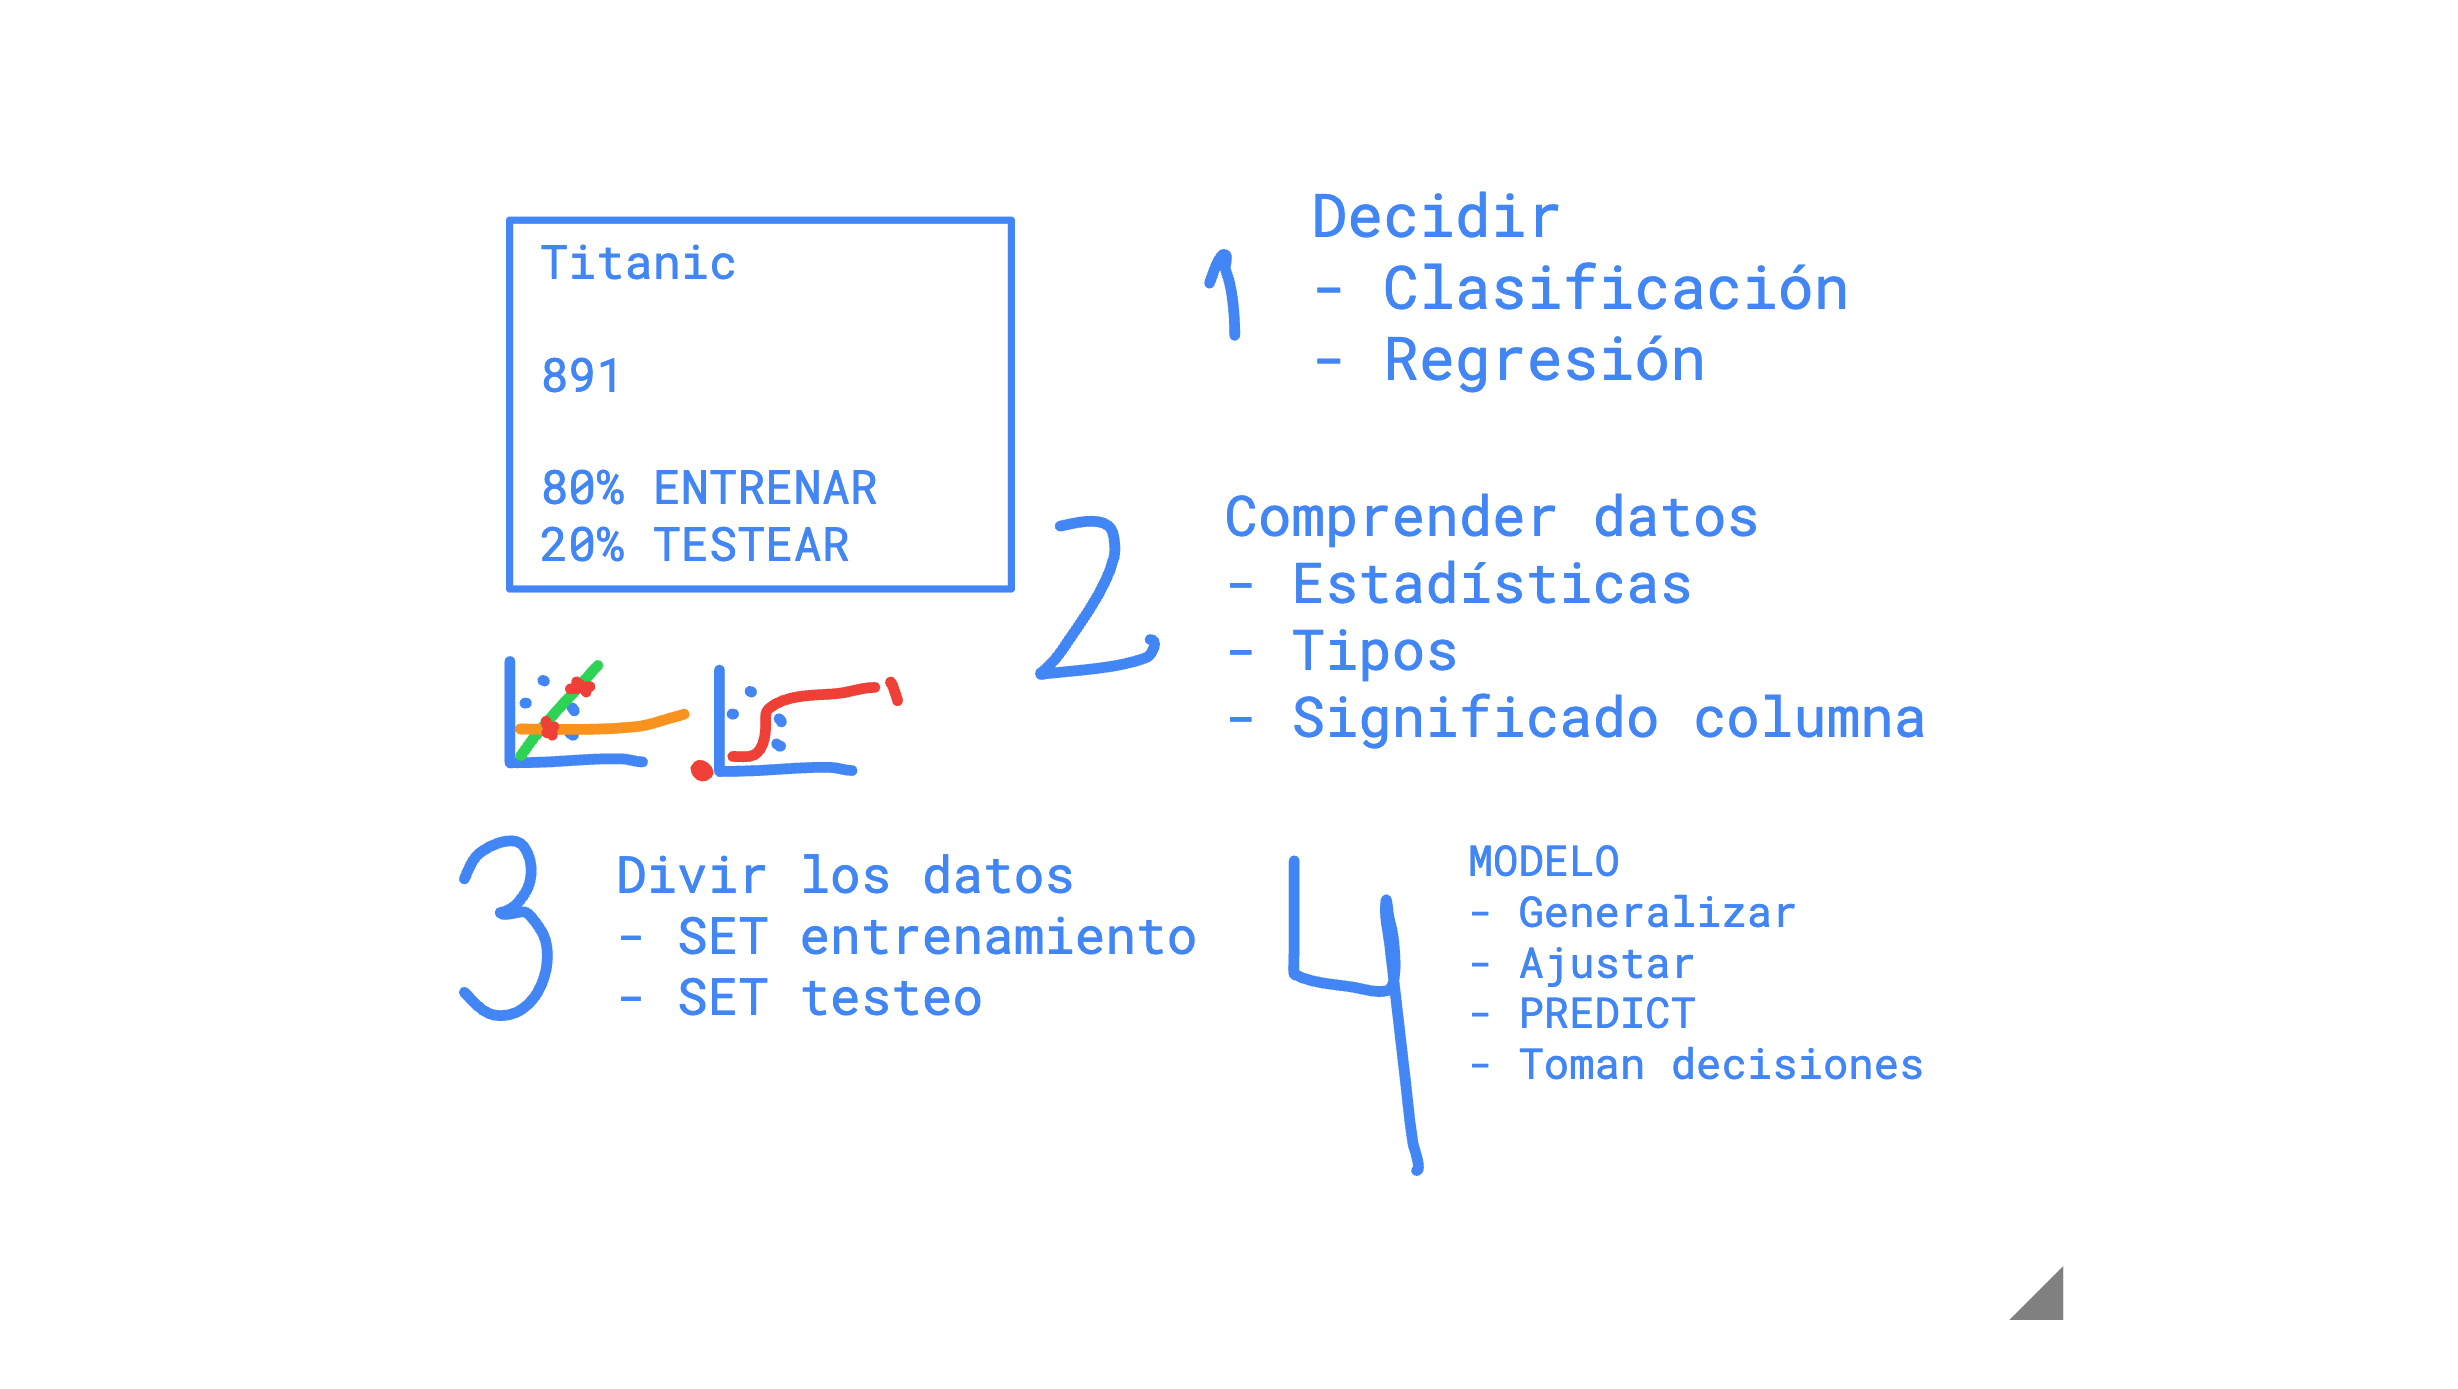

---
# Parte 3. Introducción a machine learning

## 3.1 ¿Qué es machine learning?

En la programación tradicional, una persona escribe las reglas: "si es mujer y viaja en primera clase, entonces sobrevive". En **machine learning** el programa aprende las reglas a partir de ejemplos.

Le damos al modelo:

- **X (características o features):** los datos de entrada. En el Titanic: clase, sexo, edad, tarifa, familia.
- **y (objetivo o target):** lo que queremos predecir. Aquí: `survived`.

El modelo busca una relación entre X e y. Si la encuentra, puede predecir y para pasajeros que nunca vio.

## 3.2 Tipos de problemas

| Tipo | y es... | Ejemplo | Capítulo |
|---|---|---|---|
| **Clasificación** (supervisado) | una categoría | ¿Sobrevive o no? ¿Es spam o no? | 5 |
| **Regresión** (supervisado) | un número | Precio de una casa, ventas del próximo mes | 5 |
| **Clustering** (no supervisado) | no hay y | Agrupar clientes parecidos | 6 |

Hoy resolvemos un problema de **clasificación**.

## 3.3 El flujo de trabajo

Casi todo proyecto de machine learning sigue estos pasos, y los vamos a repetir durante todo el curso:

1. Preparar los datos: limpiar, rellenar faltantes, convertir texto a números.
2. Separar X e y.
3. Dividir en entrenamiento y prueba.
4. Entrenar el modelo con `fit`.
5. Predecir con `predict`.
6. Evaluar con métricas.

## 3.4 Preparar los datos

Los modelos de scikit-learn solo entienden **números** y **no aceptan valores faltantes**. Por eso:

- `sex` (texto) se convierte en 0 y 1.
- `embarked` (tres categorías) se convierte con **one-hot encoding**: una columna de 0/1 por cada categoría. No usamos 0, 1 y 2 porque el modelo interpretaría que Q "es mayor" que C, lo que no tiene sentido.

Partimos desde una copia limpia del dataset para que esta parte funcione aunque los ejercicios anteriores no estén resueltos.

In [ ]:
datos = sns.load_dataset("titanic")[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]].copy()
datos

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,NaN,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


In [ ]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [ ]:
# 1. Rellenar faltantes
datos["age"] = datos["age"].fillna(datos.groupby("pclass")["age"].transform("median"))
datos["embarked"] = datos["embarked"].fillna(datos["embarked"].mode()[0])

In [ ]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       891 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  891 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [ ]:
datos["sex"] = datos["sex"].map({"male": 0, "female": 1})
datos = pd.get_dummies(datos, columns=["embarked"], dtype=int)

In [ ]:
datos

,survived,pclass,sex,age,sibsp,parch,fare,embarked_C,embarked_Q,embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1
...,...,...,...,...,...,...,...,...,...,...
886,0,2,0,27.0,0,0,13.0000,0,0,1
887,1,1,1,19.0,0,0,30.0000,0,0,1
888,0,3,1,24.0,1,2,23.4500,0,0,1
889,1,1,0,26.0,0,0,30.0000,1,0,0


In [ ]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   survived    891 non-null    int64  
 1   pclass      891 non-null    int64  
 2   sex         891 non-null    int64  
 3   age         891 non-null    float64
 4   sibsp       891 non-null    int64  
 5   parch       891 non-null    int64  
 6   fare        891 non-null    float64
 7   embarked_C  891 non-null    int64  
 8   embarked_Q  891 non-null    int64  
 9   embarked_S  891 non-null    int64  
dtypes: float64(2), int64(8)
memory usage: 69.7 KB


In [ ]:
datos = sns.load_dataset("titanic")[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]].copy()

# 1. Rellenar faltantes
datos["age"] = datos["age"].fillna(datos.groupby("pclass")["age"].transform("median"))
datos["embarked"] = datos["embarked"].fillna(datos["embarked"].mode()[0])

# 2. Convertir texto a números
datos["sex"] = datos["sex"].map({"male": 0, "female": 1})
datos = pd.get_dummies(datos, columns=["embarked"], dtype=int)

print("Faltantes totales:", datos.isna().sum().sum())
datos.head()

In [ ]:
print("Faltantes totales:", datos.isna().sum().sum())
datos.head()

Faltantes totales: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked_C,embarked_Q,embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


## 3.5 Separar X e y, y dividir en entrenamiento y prueba

Esta es la idea más importante de la clase. Si evaluamos al modelo con los mismos datos con que aprendió, es como tomar una prueba habiendo visto las respuestas: la nota no dice nada sobre si aprendió.

Por eso guardamos una parte de los datos (aquí, 20%) que el modelo **nunca ve** durante el entrenamiento, y lo evaluamos con ella.

- `test_size=0.2`: 20% para prueba.
- `random_state=42`: la división es reproducible.
- `stratify=y`: mantiene la misma proporción de sobrevivientes en ambos grupos.

In [ ]:
from sklearn.model_selection import train_test_split

X = datos.drop(columns="survived")
y = datos["survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Tasa de supervivencia en train:", round(y_train.mean(), 3), "| en test:", round(y_test.mean(), 3))

Entrenamiento: (712, 9) | Prueba: (179, 9)
Tasa de supervivencia en train: 0.383 | en test: 0.385


## 3.6 La línea base: ¿cuánto acierta un modelo sin cerebro?

Antes de entrenar, conviene saber cuánto acierta la estrategia más tonta posible: predecir siempre la clase más frecuente ("nadie sobrevive"). Cualquier modelo útil tiene que superar esta **línea base**.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

base = DummyClassifier(strategy="most_frequent")
base.fit(X_train, y_train)
print("Exactitud de la línea base:", round(accuracy_score(y_test, base.predict(X_test)), 3))

Exactitud de la línea base: 0.615


Predecir "nadie sobrevive" acierta cerca del 62%. Eso no es un buen modelo; solo refleja que la mayoría murió. Recuerda este número.

## 3.7 Entrenar el primer modelo: regresión logística

Toda la API de scikit-learn funciona igual, sea cual sea el modelo:

```python
modelo = AlgunModelo(parametros)
modelo.fit(X_train, y_train)      # aprender
predicciones = modelo.predict(X_test)  # predecir
```

La **regresión logística**, a pesar de su nombre, es un modelo de clasificación. Calcula la probabilidad de que y sea 1 combinando las características con pesos que aprende de los datos. La veremos en detalle en el capítulo 5.

In [ ]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)
print("Primeras 10 predicciones:", pred[:10])
print("Primeros 10 valores reales:", y_test.values[:10])
print("Exactitud en prueba:", round(accuracy_score(y_test, pred), 3))

Primeras 10 predicciones: [0 0 0 0 1 0 1 0 0 0]
Primeros 10 valores reales: [0 0 1 0 1 1 1 0 0 0]
Exactitud en prueba: 0.81


## 3.8 Evaluar más allá de la exactitud

La **exactitud** (accuracy) es la proporción de aciertos. Es útil, pero no dice **en qué** se equivoca el modelo. Para eso usamos la **matriz de confusión**:

|  | Predice 0 | Predice 1 |
|---|---|---|
| **Real 0** | Verdaderos negativos | Falsos positivos |
| **Real 1** | Falsos negativos | Verdaderos positivos |

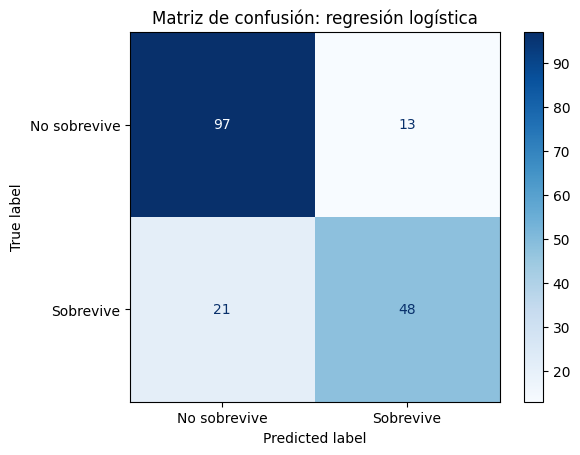

              precision    recall  f1-score   support

No sobrevive       0.82      0.88      0.85       110
   Sobrevive       0.79      0.70      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No sobrevive", "Sobrevive"], cmap="Blues")
plt.title("Matriz de confusión: regresión logística")
plt.show()

print(classification_report(y_test, pred, target_names=["No sobrevive", "Sobrevive"]))

En el reporte:

- **Precision** de "Sobrevive": de los que el modelo dijo que sobrevivían, qué proporción realmente sobrevivió.
- **Recall** de "Sobrevive": de los que realmente sobrevivieron, qué proporción detectó el modelo.

Profundizaremos en estas métricas en el capítulo 5.

## 3.9 Predecir para pasajeros nuevos

Un modelo entrenado sirve para casos que no existían en los datos. `predict_proba` entrega la probabilidad de cada clase.

In [ ]:
nuevos = pd.DataFrame({
    "pclass":     [1, 3],
    "sex":        [1, 0],      # 1 = mujer, 0 = hombre
    "age":        [30, 25],
    "sibsp":      [0, 0],
    "parch":      [0, 0],
    "fare":       [80.0, 7.5],
    "embarked_C": [1, 0],
    "embarked_Q": [0, 0],
    "embarked_S": [0, 1],
})[X.columns]   # mismas columnas y en el mismo orden que X

prob = modelo.predict_proba(nuevos)[:, 1]
for desc, p in zip(["Mujer, 30 años, primera clase", "Hombre, 25 años, tercera clase"], prob):
    print(f"{desc}: {p:.1%} de probabilidad de sobrevivir")

Mujer, 30 años, primera clase: 95.3% de probabilidad de sobrevivir
Hombre, 25 años, tercera clase: 9.9% de probabilidad de sobrevivir


## 3.10 Otro modelo: árbol de decisión y sobreajuste

Un **árbol de decisión** aprende una serie de preguntas del tipo "¿sex = mujer?", "¿pclass ≤ 2?". Es fácil de interpretar, pero tiene un riesgo: si lo dejamos crecer sin límite, **memoriza** los datos de entrenamiento en vez de aprender patrones generales. A eso se le llama **sobreajuste** (overfitting).

El parámetro `max_depth` limita cuántas preguntas seguidas puede hacer. Observa qué pasa con la exactitud en entrenamiento y en prueba al aumentarlo:

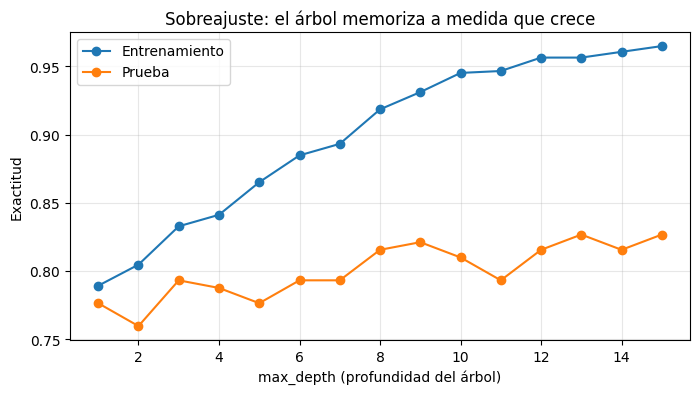

In [ ]:
from sklearn.tree import DecisionTreeClassifier

profundidades = range(1, 16)
exac_train, exac_test = [], []
for d in profundidades:
    arbol = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    exac_train.append(arbol.score(X_train, y_train))
    exac_test.append(arbol.score(X_test, y_test))

plt.figure(figsize=(8, 4))
plt.plot(profundidades, exac_train, marker="o", label="Entrenamiento")
plt.plot(profundidades, exac_test, marker="o", label="Prueba")
plt.xlabel("max_depth (profundidad del árbol)")
plt.ylabel("Exactitud")
plt.title("Sobreajuste: el árbol memoriza a medida que crece")
plt.legend(); plt.grid(alpha=0.3); plt.show()

A medida que el árbol crece, la exactitud en entrenamiento se acerca al 100%, pero en prueba se estanca o baja. **El modelo que nos interesa es el que mejor generaliza**, es decir, el que mejor funciona en datos que no vio. Por eso siempre evaluamos con el conjunto de prueba.

Un árbol pequeño se puede dibujar y leer como un diagrama de reglas:

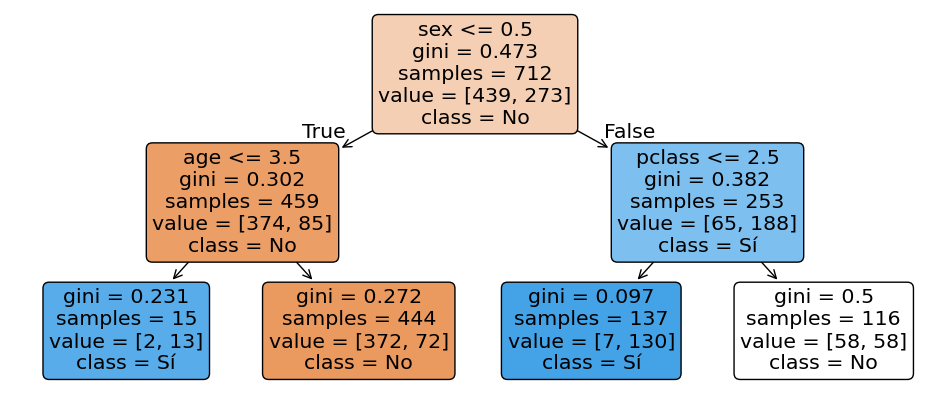

In [ ]:
from sklearn.tree import plot_tree

arbol_chico = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(12, 5))
plot_tree(arbol_chico, feature_names=X.columns, class_names=["No", "Sí"], filled=True, rounded=True)
plt.show()

## Ejercicios de machine learning

### Ejercicio 8
Entrena un `DecisionTreeClassifier` con `max_depth=4` y `random_state=42` usando `X_train` e `y_train`. Guárdalo en `arbol4` y calcula su exactitud en prueba en `exac_arbol4`.

¿Supera a la regresión logística? ¿Y a la línea base?

In [ ]:
arbol4 = None       # TU CÓDIGO AQUÍ
exac_arbol4 = None  # TU CÓDIGO AQUÍ
print("Exactitud árbol (max_depth=4):", exac_arbol4)

In [ ]:
_ref = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train).score(X_test, y_test)
revisar(lambda: np.isclose(exac_arbol4, _ref))

### Ejercicio 9
¿Mejora el modelo si le damos más información?

1. Copia `datos` en `datos2` y agrégale la columna `familia` (`sibsp + parch + 1`).
2. Separa `X2` e `y2`, y divide con **los mismos parámetros** de antes (`test_size=0.2`, `random_state=42`, `stratify=y2`).
3. Entrena una `LogisticRegression(max_iter=1000)` y guarda su exactitud en prueba en `exac_familia`.
4. Compárala con la exactitud del modelo original.

In [ ]:
# TU CÓDIGO AQUÍ


exac_familia = None
print("Exactitud con 'familia':", exac_familia)

In [ ]:
_d2 = datos.copy(); _d2["familia"] = _d2["sibsp"] + _d2["parch"] + 1
_X2, _y2 = _d2.drop(columns="survived"), _d2["survived"]
_a, _b, _c, _e = train_test_split(_X2, _y2, test_size=0.2, random_state=42, stratify=_y2)
_ref = LogisticRegression(max_iter=1000).fit(_a, _c).score(_b, _e)
revisar(lambda: np.isclose(exac_familia, _ref))

### Ejercicio 10 (análisis)
Ejecuta la siguiente celda: muestra qué importancia le da el árbol de profundidad 4 a cada característica. ¿Cuáles son las tres más importantes? ¿Coincide con lo que encontraste en la Parte 2 con `groupby`?

In [ ]:
try:
    importancias = pd.Series(arbol4.feature_importances_, index=X.columns).sort_values()
    importancias.plot(kind="barh", color="#1428A0", figsize=(7, 4), title="Importancia de cada característica")
    plt.show()
except AttributeError:
    print("Primero resuelve el Ejercicio 8.")

**Mi conclusión:** (escribe aquí con doble clic)

---
# Parte 4. Desafío final y guardar en GitHub

## Desafío: clasificar especies de pingüinos

El dataset **penguins** tiene medidas de 344 pingüinos de tres especies (Adelie, Chinstrap y Gentoo) en islas de la Antártica. Aplica el flujo completo de la clase para predecir la especie (`species`) a partir de sus medidas.

Pasos sugeridos:

1. Explora el dataset: forma, tipos, faltantes, `value_counts` de la especie.
2. Elimina las filas con faltantes (son pocas).
3. Usa como X las columnas numéricas: `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`.
4. Divide en entrenamiento y prueba (20%, `random_state=42`, estratificado).
5. Calcula la línea base, entrena una regresión logística y un árbol de decisión, y compara sus exactitudes.
6. Muestra la matriz de confusión del mejor modelo.

**Extra:** agrega `island` y `sex` como características con one-hot encoding. ¿Mejora el modelo?

In [ ]:
pinguinos = sns.load_dataset("penguins")
pinguinos.head()

In [ ]:
# TU CÓDIGO AQUÍ

## Guardar tu trabajo en GitHub

Con lo que vimos el jueves, guarda este notebook en tu repositorio:

1. *Archivo > Guardar una copia en GitHub*.
2. Autoriza a Colab a acceder a tu cuenta de GitHub, si te lo pide.
3. Elige tu repositorio y la rama `main`.
4. Escribe un mensaje de commit descriptivo, por ejemplo: `Clase 2: NumPy, pandas e intro a ML`.
5. Marca la opción *Incluir un enlace a Colab* y confirma.

Repositorio del curso: https://github.com/davidlealo/sic_ia_2026

---
# Soluciones

Intenta resolver cada ejercicio antes de mirar aquí. Si ejecutas estas celdas, se sobrescriben tus variables con la solución.

### Ejercicio 1

In [ ]:
pares = np.arange(0, 21, 2)
revisar(lambda: np.array_equal(pares, np.arange(0, 21, 2)))

### Ejercicio 2

In [ ]:
temp_f = temp_c * 9 / 5 + 32
dias_calurosos = (temp_c > 25).sum()
print(temp_f.round(1), "| días calurosos:", dias_calurosos)

### Ejercicio 3

In [ ]:
prom_eval = notas_curso.mean(axis=0)
prom_est = notas_curso.mean(axis=1)
n_aprobados = (prom_est >= 4.0).sum()
print(prom_eval.round(2), "| aprobados:", n_aprobados)

### Ejercicio 4

In [ ]:
tasa_por_puerto = titanic.groupby("embarked")["survived"].mean().sort_values(ascending=False)
tasa_por_puerto

### Ejercicio 5

In [ ]:
titanic["familia"] = titanic["sibsp"] + titanic["parch"] + 1
titanic["viaja_solo"] = titanic["familia"] == 1
tasa_solo = titanic.groupby("viaja_solo")["survived"].mean()
tasa_solo

### Ejercicio 6

In [ ]:
titanic["age"] = titanic["age"].fillna(titanic.groupby("pclass")["age"].transform("median"))
print("Faltantes en age:", titanic["age"].isna().sum())

### Ejercicio 7
Los hombres de tercera clase tuvieron la tasa más baja, cercana al 14%.

In [ ]:
pd.pivot_table(titanic, values="survived", index="sex", columns="pclass", aggfunc="mean").round(3)

### Ejercicio 8

In [ ]:
arbol4 = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)
exac_arbol4 = arbol4.score(X_test, y_test)
print("Árbol:", round(exac_arbol4, 3), "| Logística:", round(accuracy_score(y_test, pred), 3), "| Base:", round(base.score(X_test, y_test), 3))

### Ejercicio 9

In [ ]:
datos2 = datos.copy()
datos2["familia"] = datos2["sibsp"] + datos2["parch"] + 1
X2 = datos2.drop(columns="survived")
y2 = datos2["survived"]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)
exac_familia = LogisticRegression(max_iter=1000).fit(X2_train, y2_train).score(X2_test, y2_test)
print("Con familia:", round(exac_familia, 3), "| Original:", round(accuracy_score(y_test, pred), 3))

Una característica nueva no siempre mejora el modelo. `familia` es la suma de `sibsp` y `parch`, que ya estaban en X, así que aporta poca información nueva a un modelo lineal.

### Ejercicio 10
Las características más importantes suelen ser `sex`, `pclass` y `age` (o `fare`). Coincide con el análisis de la Parte 2: el sexo y la clase fueron los factores que más separaron a sobrevivientes de no sobrevivientes.

### Desafío final

In [ ]:
p = sns.load_dataset("penguins").dropna()
print(p["species"].value_counts())

cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
Xp, yp = p[cols], p["species"]
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yp, test_size=0.2, random_state=42, stratify=yp)

modelos = {
    "Línea base": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": LogisticRegression(max_iter=5000),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=4, random_state=42),
}
for nombre, m in modelos.items():
    m.fit(Xp_tr, yp_tr)
    print(f"{nombre}: {m.score(Xp_te, yp_te):.3f}")

ConfusionMatrixDisplay.from_estimator(modelos["Regresión logística"], Xp_te, yp_te, cmap="Blues")
plt.title("Pingüinos: regresión logística")
plt.show()

In [ ]:
# Extra: agregar isla y sexo con one-hot encoding
Xp2 = pd.get_dummies(p[cols + ["island", "sex"]], columns=["island", "sex"], dtype=int)
Xa, Xb, ya, yb = train_test_split(Xp2, yp, test_size=0.2, random_state=42, stratify=yp)
print("Logística con isla y sexo:", round(LogisticRegression(max_iter=5000).fit(Xa, ya).score(Xb, yb), 3))